# MGS-20 : Langage de composition pour métaheuristiques (jumeau C#)

[← MGS-19 Métropolis](MGS-19-MetropolisReinsertion.ipynb) | [↑ Série MGS](README.md) | [MGS-21 Représentation vs Algorithme](MGS-21-Representation-vs-Algorithme.ipynb)

**Série** : Search · Partie 4 (Métaheuristiques)
**Carnet jumeau** : [MGS-20-Langage-de-Composition.ipynb](MGS-20-Langage-de-Composition.ipynb) (Python) — même plan, mêmes expériences, réalisations aléatoires distinctes.
**Pré-requis** : MGS-02 (composition de métaheuristiques — primitives et combinateurs) et MGS-19 (opérateurs décomposés).

## Ce que ce carnet fait de différent

Le carnet Python écrit son mini-DSL au-dessus de `numpy` : une population est un `ndarray`, la boucle évolutionnaire est une boucle Python, et les opérateurs sont des objets `__call__`. Ce carnet écrit le **même langage** en C#, au-dessus du **moteur de la série** : `MetaGeneticSharp`, la bibliothèque que MGS-04/05/11/19 chargent déjà par `#r`. Le vocabulaire n'est donc pas décoratif — chaque primitive du DSL nomme une classe réelle du moteur (`Mutate` pour `MutationMetaHeuristic`, `Select` pour `SelectionMetaHeuristic`, etc.), et la section 8 **branche le moteur natif sur le même paysage** pour confronter une composition du DSL à une exécution de `MetaGeneticAlgorithm`.

## Objectifs pédagogiques

1. Passer de l'**écriture manuelle** d'une composition d'opérateurs (`Seq(Mutate, Select)` à la main) à une **recherche par spécification** : on décrit le comportement souhaité, on cherche la composition qui le réalise.
2. Découvrir un **mini-DSL** (3 primitives + 4 combinateurs) et une **boucle évolutionnaire paramétrique** qui prend une composition arbitraire et la déroule sur N générations.
3. Écrire une **spécification comportementale** (`ScoreEarlyDive`) qui distingue une composition « plongée précoce + raffinement » d'une composition « descente lente ».
4. Implémenter un **chercheur aléatoire borné** qui génère N compositions et garde la meilleure selon la spécification, puis comparer à une composition écrite à la main (discrimination Prong B : cas non trivial qui distingue le moteur d'une baseline triviale).
5. Exercices, répartis après la section qu'ils prolongent : un cinquième combinateur (`Islands`), une troisième spécification (le meilleur jamais atteint), et une recherche gloutonne à la place du tirage aléatoire.

## Plan du notebook

| # | Section | Thème | Sortie attendue |
|---|---------|-------|-----------------|
| 1 | Motivation | Pourquoi un langage ? | Justification du mini-DSL |
| 2 | Mini-DSL | 3 primitives + 4 combinateurs | `Operator`, `Mutate`, `Crossover`, `Select`, `Seq`, `Switch`, `Repeat`, `ParallelOp` |
| 3 | Boucle évolutionnaire | Paramétrique sur composition | `Evolve(composition, ...)` |
| 4 | Spécifications comportementales | `ScoreEarlyDive` + `ScoreFastFirstHit` | Deux fonctions de score |
| 5 | Chercheur aléatoire | Recherche bornée en profondeur | `GenerateCandidate(rng, maxDepth: 3)` |
| 6 | Visualisation | Discrimination Prong B | Courbes médianes du top 5 (SVG statique) |
| 7 | Comparaison honnête | Main contre trouvée, 20 graines | Table médiane + écart-type |
| 8 | Pont moteur natif | DSL contre `MetaGeneticAlgorithm` | Table et courbes comparées |
| 9 | Conclusion honnête | Ce que le carnet démontre | Résultats mesurés + nuances |

Les renvois « section N » de la prose désignent les lignes de ce tableau.

**Exercices** : trois, répartis dans le carnet — un cinquième combinateur après la section 2, une troisième spécification après la section 6, une recherche gloutonne après la section 7.

**Coût** : les cellules coûteuses impriment leur durée sur le run committé ; les valeurs sont rappelées dans la conclusion.

**Concepts clés** : DSL (langage dédié), composition d'opérateurs, spécification comportementale (par opposition à l'optimisation d'un scalaire final), recherche aléatoire, recherche gloutonne, modèle en îles, comparaison honnête main contre trouvée.

**Références** : Fortin et al. 2012 (DEAP, *JMLR* 13:2171-2175), Real et al. 2020 (AutoML-Zero, *ICML*, PMLR 119), Stanley et Miikkulainen 2002 (NEAT, *Evolutionary Computation* 10(2):99-127) ; MGS-04 et MGS-19 (carnets précédents de la série). Ces trois publications sont archivées dans le gisement bibliographique du projet, et le carnet ne leur attribue que ce que leur texte dit.

## Prérequis d'exécution

- Noyau `.net-csharp` ; la première cellule imprime le runtime réellement chargé, et les DLL du fork ciblent `net9.0`.
- Les DLL du fork `MetaGeneticSharp` construites dans le sous-module : `../MetaGeneticSharp/src/MetaGeneticSharp.Domain/bin/Debug/net9.0/` et `../MetaGeneticSharp/src/MetaGeneticSharp.Extensions/bin/Debug/net9.0/`.
- Le helper SVG de la série Probas, `#load "../../Probas/Infer/SvgChartHelper.cs"` : rendu statique, sans JavaScript ni CDN.

In [1]:
// Cablage : les DLL du fork MetaGeneticSharp, memes chemins relatifs que MGS-19
// (le noyau demarre dans le dossier du carnet).
#r "../MetaGeneticSharp/src/MetaGeneticSharp.Domain/bin/Debug/net9.0/GeneticSharp.Infrastructure.Framework.dll"
#r "../MetaGeneticSharp/src/MetaGeneticSharp.Domain/bin/Debug/net9.0/GeneticSharp.Domain.dll"
#r "../MetaGeneticSharp/src/MetaGeneticSharp.Domain/bin/Debug/net9.0/MetaGeneticSharp.Infrastructure.dll"
#r "../MetaGeneticSharp/src/MetaGeneticSharp.Domain/bin/Debug/net9.0/MetaGeneticSharp.Domain.dll"
#r "../MetaGeneticSharp/src/MetaGeneticSharp.Extensions/bin/Debug/net9.0/MetaGeneticSharp.Extensions.dll"

// Le generateur de figures statiques de la serie Probas : SVG en ligne, zero dependance.
#load "../../Probas/Infer/SvgChartHelper.cs"

using System;
using System.Collections.Generic;
using System.Diagnostics;
using System.Globalization;
using System.Linq;
using System.Runtime.CompilerServices;
using System.Text;
using MetaGeneticSharp;
using GeneticSharp;

// Affichage invariant. Le noyau execute chaque cellule sur un thread qui repart de la
// culture du poste : sur un Windows francais, un format "0.000" ecrirait "0,995", et un
// attribut SVG "x=\"108,62\"" serait invalide. Chaque nombre imprime passe donc par une
// conversion explicite, pour que les sorties commitees soient identiques d'une machine
// a l'autre.
public static class Fmt
{
    public static string Num(double value, string format = "0.0000")
        => value.ToString(format, CultureInfo.InvariantCulture);
}

// Alias court pour le code de haut niveau des cellules. Les classes du carnet appellent
// Fmt.Num : une fonction locale de script n'est pas accessible depuis un type declare
// au meme niveau.
string Num(double value, string format = "0.0000") => Fmt.Num(value, format);

// Le constructeur statique du helper enregistre le formatter SvgChart (SVG inline, deux
// types MIME). La premiere figure du carnet est composee a la main, sans passer par une
// methode du helper : on force donc l'initialisation du type ici, une fois pour toutes.
RuntimeHelpers.RunClassConstructor(typeof(SvgChartHelper).TypeHandle);

// Domaine canonique du paysage Rastrigin 2D, partage par toutes les cellules.
const double Lo = -5.12;
const double Hi = 5.12;

Console.WriteLine($"Runtime .NET : {Environment.Version}");
Console.WriteLine();
Console.WriteLine("Classes du moteur que le vocabulaire de ce carnet nomme :");
Console.WriteLine($"  Mutate(...)    -> {nameof(MutationMetaHeuristic)}");
Console.WriteLine($"  Crossover(...) -> {nameof(CrossoverMetaHeuristic)}");
Console.WriteLine($"  Select(...)    -> {nameof(SelectionMetaHeuristic)}");
Console.WriteLine($"  Seq / Repeat   -> {nameof(ContainerMetaHeuristic)}, {nameof(SizeBasedMetaHeuristic)}");
Console.WriteLine($"  Switch(...)    -> {nameof(SwitchMetaHeuristic<int>)}");
Console.WriteLine($"  exercice 1     -> {nameof(IslandMetaHeuristic)}");
Console.WriteLine($"  moteur/fitness -> {nameof(MetaGeneticAlgorithm)}, {nameof(RastriginFitness)}");

Runtime .NET : 10.0.13


Classes du moteur que le vocabulaire de ce carnet nomme :


  Mutate(...)    -> MutationMetaHeuristic


  Crossover(...) -> CrossoverMetaHeuristic


  Select(...)    -> SelectionMetaHeuristic


  Seq / Repeat   -> ContainerMetaHeuristic, SizeBasedMetaHeuristic


  Switch(...)    -> SwitchMetaHeuristic


  exercice 1     -> IslandMetaHeuristic


  moteur/fitness -> MetaGeneticAlgorithm, RastriginFitness


### Lecture du câblage

Trois familles d'assemblies sont chargées, et une seule sert vraiment au DSL :

1. **`GeneticSharp.*`** — le socle amont : `IChromosome`, `ChromosomeBase`, `Gene`, `IFitness`, les opérateurs de croisement et de mutation classiques. Il n'est utilisé ici qu'à la section 8, pour le pont natif.
2. **`MetaGeneticSharp.Domain`** — le fork de la série : les métaheuristiques composables (`MutationMetaHeuristic`, `CrossoverMetaHeuristic`, `SelectionMetaHeuristic`, `ContainerMetaHeuristic`, `SwitchMetaHeuristic<T>`, `SizeBasedMetaHeuristic`, `IslandMetaHeuristic`) et le moteur `MetaGeneticAlgorithm` avec sa `MetaPopulation`. C'est **ce** vocabulaire que le DSL du carnet nomme.
3. **`MetaGeneticSharp.Extensions`** — les fonctions de test du fork, dont `RastriginFitness` (bornes `[-5.12, 5.12]`, exactement le domaine du jumeau Python) et les helpers `Optimizer` / `OptimizerRequest` déjà utilisés par MGS-10, MGS-11 et MGS-19.

**Pourquoi charger l'organe si le carnet réimplémente une boucle ?** Parce que les deux ne jouent pas le même rôle. Le DSL est un **objet d'étude** : un langage dont on cherche les programmes, dont l'implémentation doit rester lisible ligne à ligne. Le moteur natif est l'**organe de la série** : il sait déjà exécuter une génération, réinsérer, terminer sur un critère. Les deux sont mis côte à côte à la section 8, au lieu de laisser croire que le DSL remplace le moteur.

**Note sur le helper SVG.** `#load "../../Probas/Infer/SvgChartHelper.cs"` charge le générateur de figures statiques de la série Probas : une figure est un `<svg>` en ligne, sans JavaScript, sans CDN, sans installation. Le jumeau Python trace avec `matplotlib` et enregistre des PNG ; ici les figures vivent dans la sortie de la cellule, ce qui évite un fichier binaire de plus dans le dépôt. Le helper enregistre son formatter dans un **constructeur statique** : il ne s'exécute qu'au premier accès au type, et la première figure du carnet est composée à la main, sans passer par une méthode du helper. D'où la ligne `RuntimeHelpers.RunClassConstructor(typeof(SvgChartHelper).TypeHandle)` — sans elle, un `SvgChart` s'afficherait comme un objet ordinaire au lieu d'une image.

**Note sur les nombres affichés.** Le noyau .NET Interactive exécute chaque cellule sur un thread qui repart de la culture du poste : sur un Windows français, un format `0.000` écrit `0,995`. Une affectation `CultureInfo.CurrentCulture` faite dans une cellule ne survit donc pas à la cellule suivante — et, plus grave, un attribut SVG du type `x="108,62"` serait invalide et la figure ne s'afficherait pas. Tous les nombres passent donc par `Num(valeur, format)`, qui convertit explicitement en culture invariante : trois caractères de plus par appel, et des sorties identiques sur toutes les machines.

Domaine          : [-5.12, 5.12]^2


Grille           : 200 x 200 = 40000 points


f min sur grille : 0.2621 atteint en (-0.0257, -0.0257)


f max sur grille : 80.5427


f(0, 0)          : 0.0000


f(1, 1)          : 2.0000


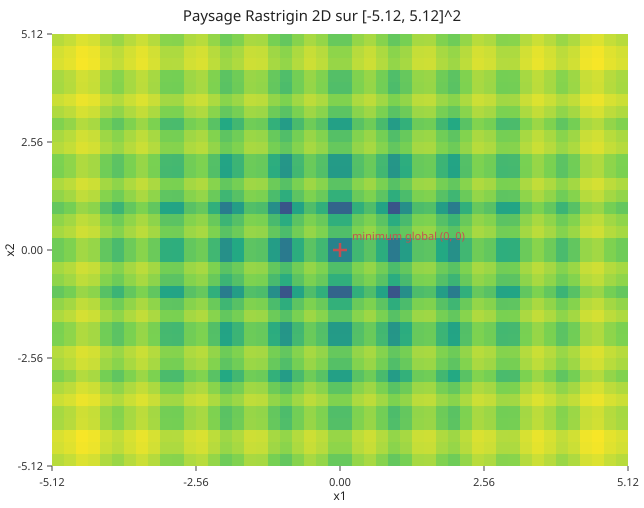

In [2]:
// Fonction de Rastrigin 2D : f(0,0) = 0 est le minimum global, et le domaine
// [-5.12, 5.12]^2 contient une centaine d'optima locaux -- le piege classique
// de toute methode de descente pure.
double Rastrigin(double[] x)
{
    double s = 10.0 * x.Length;
    foreach (var xi in x) s += xi * xi - 10.0 * Math.Cos(2.0 * Math.PI * xi);
    return s;
}

// Statistiques sur une grille 200 x 200 : la cellule imprime des nombres mesurables,
// la figure qui suit les rend lisibles.
const int GridN = 200;
var gridMin = double.PositiveInfinity;
var gridMax = double.NegativeInfinity;
var gridArgMin = (0.0, 0.0);
for (int i = 0; i < GridN; i++)
{
    double x1 = Lo + (Hi - Lo) * i / (GridN - 1);
    for (int j = 0; j < GridN; j++)
    {
        double x2 = Lo + (Hi - Lo) * j / (GridN - 1);
        double v = Rastrigin(new[] { x1, x2 });
        if (v < gridMin) { gridMin = v; gridArgMin = (x1, x2); }
        if (v > gridMax) gridMax = v;
    }
}

Console.WriteLine($"Domaine          : [{Num(Lo, "0.00")}, {Num(Hi, "0.00")}]^2");
Console.WriteLine($"Grille           : {GridN} x {GridN} = {GridN * GridN} points");
Console.WriteLine($"f min sur grille : {Num(gridMin)} atteint en ({Num(gridArgMin.Item1)}, {Num(gridArgMin.Item2)})");
Console.WriteLine($"f max sur grille : {Num(gridMax)}");
Console.WriteLine($"f(0, 0)          : {Num(Rastrigin(new[] { 0.0, 0.0 }))}");
Console.WriteLine($"f(1, 1)          : {Num(Rastrigin(new[] { 1.0, 1.0 }))}");

// Palette viridis interpolee en RGB, utilisee par la carte ci-dessous.
string Viridis(double t)
{
    t = Math.Max(0.0, Math.Min(1.0, t));
    double[][] stops =
    {
        new[] { 0.267, 0.005, 0.329 },   // #440154
        new[] { 0.255, 0.267, 0.529 },   // #414487
        new[] { 0.165, 0.471, 0.557 },   // #2A788E
        new[] { 0.133, 0.659, 0.518 },   // #22A884
        new[] { 0.478, 0.821, 0.318 },   // #7AD151
        new[] { 0.992, 0.906, 0.145 },   // #FDE725
    };
    double pos = t * (stops.Length - 1);
    int k = Math.Min((int)pos, stops.Length - 2);
    double f = pos - k;
    int r = (int)Math.Round(255 * (stops[k][0] + f * (stops[k + 1][0] - stops[k][0])));
    int g = (int)Math.Round(255 * (stops[k][1] + f * (stops[k + 1][1] - stops[k][1])));
    int b = (int)Math.Round(255 * (stops[k][2] + f * (stops[k + 1][2] - stops[k][2])));
    return $"#{r:X2}{g:X2}{b:X2}";
}

// Coordonnee SVG : toujours en culture invariante, sinon le separateur decimal du poste
// rendrait l'attribut invalide.
string P(double v) => Num(v, "0.##");

// Figure statique : 48 x 36 cellules echantillonnees au centre, echelle logarithmique sur
// la couleur (Rastrigin s'etale de 0 a ~80 sur ce domaine), croix rouge au minimum global.
const int Cols = 48, Rows = 36;
const double CellW = 12.0, CellH = 12.0;
const double MarL = 52.0, MarT = 34.0, MarB = 42.0, MarR = 16.0;
double plotW = Cols * CellW, plotH = Rows * CellH;
double svgW = MarL + plotW + MarR, svgH = MarT + plotH + MarB;

var svg = new StringBuilder();
svg.Append($"<svg xmlns=\"http://www.w3.org/2000/svg\" width=\"{P(svgW)}\" height=\"{P(svgH)}\" viewBox=\"0 0 {P(svgW)} {P(svgH)}\" font-family=\"sans-serif\">");
svg.Append("<rect width=\"100%\" height=\"100%\" fill=\"white\"/>");
svg.Append($"<text x=\"{P(svgW / 2)}\" y=\"21\" text-anchor=\"middle\" font-size=\"15\" fill=\"#222222\">Paysage Rastrigin 2D sur [-5.12, 5.12]^2</text>");

for (int row = 0; row < Rows; row++)
{
    double x2 = Hi - (Hi - Lo) * (row + 0.5) / Rows;
    for (int col = 0; col < Cols; col++)
    {
        double x1 = Lo + (Hi - Lo) * (col + 0.5) / Cols;
        double v = Rastrigin(new[] { x1, x2 });
        double t = Math.Log(1.0 + v) / Math.Log(1.0 + gridMax);
        svg.Append($"<rect x=\"{P(MarL + col * CellW)}\" y=\"{P(MarT + row * CellH)}\" "
            + $"width=\"{P(CellW)}\" height=\"{P(CellH)}\" fill=\"{Viridis(t)}\"/>");
    }
}

// Axes et graduations.
double MapX(double x1) => MarL + (x1 - Lo) / (Hi - Lo) * plotW;
double MapY(double x2) => MarT + (Hi - x2) / (Hi - Lo) * plotH;
var ticks = new[] { -5.12, -2.56, 0.0, 2.56, 5.12 };
foreach (var tk in ticks)
{
    svg.Append($"<line x1=\"{P(MapX(tk))}\" y1=\"{P(MarT + plotH)}\" x2=\"{P(MapX(tk))}\" y2=\"{P(MarT + plotH + 5)}\" stroke=\"#444444\"/>");
    svg.Append($"<text x=\"{P(MapX(tk))}\" y=\"{P(MarT + plotH + 20)}\" text-anchor=\"middle\" font-size=\"11\" fill=\"#333333\">{Num(tk, "0.00")}</text>");
    svg.Append($"<line x1=\"{P(MarL - 5)}\" y1=\"{P(MapY(tk))}\" x2=\"{P(MarL)}\" y2=\"{P(MapY(tk))}\" stroke=\"#444444\"/>");
    svg.Append($"<text x=\"{P(MarL - 9)}\" y=\"{P(MapY(tk) + 4)}\" text-anchor=\"end\" font-size=\"11\" fill=\"#333333\">{Num(tk, "0.00")}</text>");
}
svg.Append($"<text x=\"{P(MarL + plotW / 2)}\" y=\"{P(svgH - 8)}\" text-anchor=\"middle\" font-size=\"12\" fill=\"#222222\">x1</text>");
svg.Append($"<text x=\"14\" y=\"{P(MarT + plotH / 2)}\" text-anchor=\"middle\" font-size=\"12\" fill=\"#222222\" transform=\"rotate(-90 14 {P(MarT + plotH / 2)})\">x2</text>");

// Minimum global en (0, 0) : croix rouge.
svg.Append($"<line x1=\"{P(MapX(0) - 7)}\" y1=\"{P(MapY(0))}\" x2=\"{P(MapX(0) + 7)}\" y2=\"{P(MapY(0))}\" stroke=\"#C44E52\" stroke-width=\"2.5\"/>");
svg.Append($"<line x1=\"{P(MapX(0))}\" y1=\"{P(MapY(0) - 7)}\" x2=\"{P(MapX(0))}\" y2=\"{P(MapY(0) + 7)}\" stroke=\"#C44E52\" stroke-width=\"2.5\"/>");
svg.Append($"<text x=\"{P(MapX(0) + 12)}\" y=\"{P(MapY(0) - 10)}\" font-size=\"11\" fill=\"#C44E52\">minimum global (0, 0)</text>");
svg.Append("</svg>");

display(new SvgChart(svg.ToString()));

### Lecture de la définition de Rastrigin et du paysage

**Pourquoi Rastrigin ?** Parce que c'est le paysage canonique pour distinguer une *exploration* d'une *exploitation*. Il combine trois propriétés qui vont chacune piéger une famille d'algorithmes :

1. **Une tendance globale convexe** (`x1² + x2²` pour un point, et la même forme en toute dimension) : le fond du paysage descend vers l'origine. Une méthode qui suit la pente arrive donc *dans le bon bassin* — c'est ce qui rend le problème non trivial mais pas désespéré.
2. **Une modulation cosinusoïdale** (`-10·cos(2πx)` par coordonnée) : des dizaines d'optima locaux régulièrement espacés, dont les valeurs sont **proches** les unes des autres. Un algorithme qui se contente de descendre reste bloqué dans un puits voisin, avec une valeur qui *ressemble* à l'optimum global — le piège du « presque optimal ».
3. **Des bornes explicites** `[-5.12, 5.12]` : le domaine est exactement celui de la littérature, et c'est aussi celui que déclare `RastriginFitness` dans `MetaGeneticSharp.Extensions`. Le DSL et le moteur natif travaillent donc sur le même problème, ce qui rend la comparaison de la section 8 honnête.

**Ce que la cellule imprime, et ce que la figure ajoute.** Les nombres (minimum sur grille, maximum, `f(0,0)`) donnent l'échelle du paysage. La figure montre ce que les nombres cachent — *la densité des puits* : chaque tache claire est un bassin local, et un individu qui tombe entre deux crêtes doit franchir une barrière pour rejoindre un meilleur voisin.

**Trois détails techniques.**

- **`Rastrigin` prend un `double[]`, pas deux `double`** : la boucle évolutionnaire traite une population comme un tableau de vecteurs, et la dimension 2 n'est qu'un cas particulier. Le jumeau Python fait de même avec `np.atleast_2d`.
- **Le minimum sur grille est mesuré, pas supposé** : on l'imprime avec ses coordonnées au lieu d'affirmer `0.0`. L'écart au zéro théorique mesure la finesse de l'échantillonnage, et il est attendu — une grille finie ne contient pas forcément la paire `(0, 0)`.
- **La figure est du SVG écrit à la main**, pas un PNG : une grille de rectangles colorés, palette viridis interpolée en RGB, échelle logarithmique sur la couleur. Même rendu à l'écran, dans le HTML exporté, et dans un dépôt Git qui n'accueille aucun binaire.

### Motivation — pourquoi un langage pour composer des métaheuristiques ?

Un algorithme évolutionnaire est rarement *un* algorithme. C'est un **assemblage** : une sélection, un croisement, une mutation, une règle de réinsertion, un critère d'arrêt. MGS-01 écrit cet assemblage à la main (`new MetaGeneticAlgorithm(population, fitness, selection, crossover, mutation)`), MGS-02 le rend déclaratif, MGS-19 n'en échange qu'une pièce pour isoler l'effet de cette pièce. Dès qu'on veut *comparer* des assemblages, la combinatoire explose : le nombre de configurations croît comme le produit des opérateurs disponibles, et l'ordre des étapes compte autant que leur identité.

**Le passage du scalaire à la trajectoire.** La littérature optimise un nombre : le meilleur fitness final. Mais deux compositions qui finissent au même point ne se comportent pas de la même façon — l'une plonge vite puis raffine, l'autre descend lentement et régulièrement. Si la spécification ne regarde que le point d'arrivée, ces deux comportements sont **indistinguables**, et le chercheur choisit au hasard entre eux. Une spécification de *trajectoire* (`ScoreEarlyDive`, section 4) les sépare.

**Trois cas où ce besoin apparaît dans la pratique.**

1. **Apprentissage automatique** : comparer des schémas d'entraînement (préchauffage du pas, décroissance, curriculum) ne se fait pas sur la perte finale seule, sinon un schéma qui converge lentement mais sûrement est éliminé au profit d'un schéma qui a eu de la chance sur les dernières époques.
2. **Apprentissage par renforcement** : la *courbe d'apprentissage* est le livrable ; un agent qui atteint la récompense tôt et un agent qui l'atteint tard ont le même score final et ne sont pas le même agent.
3. **Métaheuristiques** : c'est le sujet de ce carnet. Une composition « plongée précoce puis raffinement » est préférable à une « descente monotone » sur un paysage multimodal — et cela ne se lit que sur la trajectoire.

**Ce que le carnet ne prétend pas.** Le mini-DSL n'est pas un langage de production : il n'a ni typage, ni optimisation, ni parallélisme, ni garantie de terminaison. C'est un **objet d'étude** — assez riche pour que la recherche de compositions ait un sens, assez petit pour se lire intégralement. Les frameworks du domaine ajoutent ce que celui-ci omet : une bibliothèque d'opérateurs étendue, la sérialisation des programmes, la distribution du calcul. DEAP et AutoML-Zero en sont deux exemples, examinés à la section 2 pour ce qu'ils changent au **statut** de la composition.

In [3]:
// Format partage : trois decimales significatives pour les signatures de composition.
const string FmtRate = "0.###";

// Generateur aleatoire du carnet : System.Random pour l'uniforme, Box-Muller pour la
// normale, Fisher-Yates pour la permutation. Le jumeau Python utilise
// np.random.default_rng(seed) : memes lois, realisations differentes.
public sealed class Rng
{
    private readonly Random _r;

    public Rng(int seed) { _r = new Random(seed); }

    public double NextDouble() => _r.NextDouble();

    public double Uniform(double lo, double hi) => lo + (hi - lo) * _r.NextDouble();

    public double Normal(double mean, double sd)
    {
        double u1 = 1.0 - _r.NextDouble();   // (0, 1] : log defini
        double u2 = _r.NextDouble();
        return mean + sd * Math.Sqrt(-2.0 * Math.Log(u1)) * Math.Cos(2.0 * Math.PI * u2);
    }

    public int NextInt(int minInclusive, int maxExclusive) => _r.Next(minInclusive, maxExclusive);

    public int[] Permutation(int n)
    {
        var a = Enumerable.Range(0, n).ToArray();
        for (int i = n - 1; i > 0; i--)
        {
            int j = _r.Next(i + 1);
            (a[i], a[j]) = (a[j], a[i]);
        }
        return a;
    }

    public int[] Choice(int n, int size) => Permutation(n).Take(size).ToArray();
}

// Contexte transmis a chaque primitive : bornes, fonction d'evaluation, avancement
// (0 = debut, 1 = derniere generation) et index de generation. C'est ce qui permet
// a Switch(early_phase, ...) de changer de regime sans recourir a un etat global.
public sealed class EvoContext
{
    public double Lo { get; init; }
    public double Hi { get; init; }
    public Func<double[], double> FitnessFn { get; init; }
    public double GenFrac { get; set; }
    public int Generation { get; set; }

    public double[] Evaluate(double[][] pop) => pop.Select(FitnessFn).ToArray();
}

// Primitive du langage : transforme (population, fitness) en nouvelle population.
// Native nomme la classe du moteur que la primitive designe dans MetaGeneticSharp.
public abstract class Operator
{
    public abstract string Native { get; }
    public abstract double[][] Apply(double[][] pop, double[] fitness, Rng rng, EvoContext ctx);
    public abstract string Signature();
    public override string ToString() => Signature();
}

// Mutation gaussienne gene par gene : chaque gene est mute avec probabilite rate,
// bruit d'ecart-type scale, puis replie dans les bornes.
public sealed class Mutate : Operator
{
    public double Rate;
    public double Scale;

    public Mutate(double rate, double scale) { Rate = rate; Scale = scale; }

    public override string Native => nameof(MutationMetaHeuristic);

    public override double[][] Apply(double[][] pop, double[] fitness, Rng rng, EvoContext ctx)
    {
        var next = new double[pop.Length][];
        for (int i = 0; i < pop.Length; i++)
        {
            var ind = (double[])pop[i].Clone();
            for (int g = 0; g < ind.Length; g++)
                if (rng.NextDouble() < Rate)
                    ind[g] = Math.Max(ctx.Lo, Math.Min(ctx.Hi, ind[g] + rng.Normal(0.0, Scale)));
            next[i] = ind;
        }
        return next;
    }

    public override string Signature() => $"Mutate(rate={Fmt.Num(Rate, FmtRate)}, scale={Fmt.Num(Scale, FmtRate)})";
}

// Croisement uniforme par paires melangees : chaque gene est remplace par celui du
// partenaire avec probabilite rate. La permutation des partenaires reproduit
// rng.permutation du jumeau Python.
public sealed class Crossover : Operator
{
    public double Rate;

    public Crossover(double rate) { Rate = rate; }

    public override string Native => nameof(CrossoverMetaHeuristic);

    public override double[][] Apply(double[][] pop, double[] fitness, Rng rng, EvoContext ctx)
    {
        int n = pop.Length;
        var partners = rng.Permutation(n);
        var next = new double[n][];
        for (int i = 0; i < n; i++)
        {
            var child = (double[])pop[i].Clone();
            var other = pop[partners[i]];
            for (int g = 0; g < child.Length; g++)
                if (rng.NextDouble() < Rate)
                    child[g] = other[g];
            next[i] = child;
        }
        return next;
    }

    public override string Signature() => $"Crossover(rate={Fmt.Num(Rate, FmtRate)})";
}

// Selection par tournoi : on tire tournamentSize individus sans remise, le meilleur
// (fitness minimale) est retenu ; on repete jusqu'a la taille de la population.
public sealed class Select : Operator
{
    public int TournamentSize;

    public Select(int tournamentSize) { TournamentSize = tournamentSize; }

    public override string Native => nameof(SelectionMetaHeuristic);

    public override double[][] Apply(double[][] pop, double[] fitness, Rng rng, EvoContext ctx)
    {
        int n = pop.Length;
        int ts = Math.Min(TournamentSize, n);
        var next = new double[n][];
        for (int i = 0; i < n; i++)
        {
            var idx = rng.Choice(n, ts);
            int best = idx[0];
            foreach (var k in idx) if (fitness[k] < fitness[best]) best = k;
            next[i] = (double[])pop[best].Clone();
        }
        return next;
    }

    public override string Signature() => $"Select(tournament_size={TournamentSize})";
}

Console.WriteLine("Primitives du langage (3), avec la classe du moteur qu'elles nomment :");
foreach (var p in new Operator[] { new Mutate(0.3, 0.3), new Crossover(0.5), new Select(3) })
    Console.WriteLine($"  {p.Signature(),-42} -> {p.Native}");

Primitives du langage (3), avec la classe du moteur qu'elles nomment :


  Mutate(rate=0.3, scale=0.3)                -> MutationMetaHeuristic


  Crossover(rate=0.5)                        -> CrossoverMetaHeuristic


  Select(tournament_size=3)                  -> SelectionMetaHeuristic


### Lecture des trois primitives

Le contrat tient en une ligne : `Apply(population, fitness, rng, contexte)` reçoit une population et sa fitness, rend la population suivante. Trois implémentations couvrent ce que le jumeau Python appelle `Mutate`, `Crossover`, `Select`.

| Primitive | Ce qu'elle fait | Paramètres | Classe du moteur nommée |
|---|---|---|---|
| `Mutate(rate, scale)` | bruit gaussien gène par gène : muté avec probabilité `rate`, écart-type `scale`, replié dans les bornes | `rate`, `scale` | `MutationMetaHeuristic` |
| `Crossover(rate)` | croisement uniforme par paires mélangées : chaque gène remplacé par celui du partenaire avec probabilité `rate` | `rate` | `CrossoverMetaHeuristic` |
| `Select(ts)` | tournoi de `ts` individus, le meilleur (fitness **minimale**) dupliqué jusqu'à remplir la population | `ts` | `SelectionMetaHeuristic` |

**Pourquoi la propriété `Native` ?** Parce qu'un carnet qui définit son propre vocabulaire court le risque de laisser croire qu'il remplace la bibliothèque de la série. Chaque primitive déclare la classe de `MetaGeneticSharp` qu'elle désigne, et la cellule de synthèse l'imprime. C'est le geste « organe d'abord » de la série : réimplémenter est permis, à condition de nommer ce qu'on réimplémente. La section 8 paie la dette pour de bon, en branchant le moteur natif sur le même paysage.

**Pourquoi un `EvoContext` typé plutôt qu'un dictionnaire `**ctx` ?** Le jumeau Python passe un `dict` (`{"bounds", "fitness_fn", "gen_frac", "generation"}`) : souple, mais rien n'empêche une primitive de lire une clé absente, et l'erreur n'apparaît qu'à l'exécution. En C#, les quatre ingrédients sont des champs : une primitive qui écrit `ctx.hi` ne compile pas. Le prix est une classe de plus à lire, le gain est qu'une faute de frappe devient une erreur de compilation.

**Deux détails de fidélité au jumeau.**

- **La sélection minimise** (`fitness[k] < fitness[best]`) : sur Rastrigin, `0` est l'optimum, donc « meilleur » veut dire « plus petit ». Le moteur natif fait l'inverse par convention — `RastriginFitness` rend `-f`, il **maximise**. C'est une différence à garder en tête à la section 8, où les deux conventions se rencontrent.
- **Le tournoi tire sans remise** (`rng.Choice` = début d'une permutation), comme `rng.choice(n, size=ts, replace=False)` : deux copies du même individu ne comptent pas double dans un tournoi.

**Coût** : cette cellule de définitions ne calcule rien ; seule la ligne de synthèse imprime.

In [4]:
// Combinateur sequentiel : applique ses enfants l'un apres l'autre, en recalculant
// la fitness apres chaque etape (sinon Select verrait la fitness d'avant la mutation).
public sealed class Seq : Operator
{
    public Operator[] Children;

    public Seq(params Operator[] children) { Children = children; }

    public override string Native => nameof(ContainerMetaHeuristic);

    public override double[][] Apply(double[][] pop, double[] fitness, Rng rng, EvoContext ctx)
    {
        var current = pop;
        var currentFitness = fitness;
        foreach (var child in Children)
        {
            current = child.Apply(current, currentFitness, rng, ctx);
            currentFitness = ctx.Evaluate(current);
        }
        return current;
    }

    public override string Signature() => $"Seq({string.Join(", ", Children.Select(c => c.Signature()))})";
}

// Repetition : le meme enfant n fois de suite (n >= 1).
public sealed class Repeat : Operator
{
    public Operator Child;
    public int N;

    public Repeat(Operator child, int n) { Child = child; N = Math.Max(1, n); }

    public override string Native => nameof(SizeBasedMetaHeuristic);

    public override double[][] Apply(double[][] pop, double[] fitness, Rng rng, EvoContext ctx)
    {
        var current = pop;
        var currentFitness = fitness;
        for (int i = 0; i < N; i++)
        {
            current = Child.Apply(current, currentFitness, rng, ctx);
            currentFitness = ctx.Evaluate(current);
        }
        return current;
    }

    public override string Signature() => $"Repeat({Child.Signature()}, n={N})";
}

// Predicat de regime : teste (avancement, fitness) et choisit une branche.
public sealed class Pred
{
    public string Name;
    public Func<double, double[], bool> Test;

    public Pred(string name, Func<double, double[], bool> test) { Name = name; Test = test; }

    public bool Check(double genFrac, double[] fitness) => Test(genFrac, fitness);

    public override string ToString() => Name;
}

public static class Preds
{
    public static readonly Pred EarlyPhase = new Pred("early_phase", (gen, fit) => gen < 0.5);
    public static readonly Pred LatePhase = new Pred("late_phase", (gen, fit) => gen >= 0.5);
}

// Aiguillage : une seule branche s'execute selon le predicat. C'est le combinateur qui
// change de regime en cours de course -- la ou un GA canonique garde les memes operateurs
// du debut a la fin.
public sealed class Switch : Operator
{
    public Pred Predicate;
    public Operator IfTrue;
    public Operator IfFalse;

    public Switch(Pred predicate, Operator ifTrue, Operator ifFalse)
    { Predicate = predicate; IfTrue = ifTrue; IfFalse = ifFalse; }

    public override string Native => nameof(SwitchMetaHeuristic<int>);

    public override double[][] Apply(double[][] pop, double[] fitness, Rng rng, EvoContext ctx)
        => Predicate.Check(ctx.GenFrac, fitness)
            ? IfTrue.Apply(pop, fitness, rng, ctx)
            : IfFalse.Apply(pop, fitness, rng, ctx);

    public override string Signature() => $"Switch({Predicate}, {IfTrue.Signature()}, {IfFalse.Signature()})";
}

// Parallele : la premiere moitie de la population subit le premier enfant, la seconde
// moitie le second, puis les deux moities sont recollees. Nomme ParallelOp parce que
// Parallel est deja pris par System.Threading.Tasks dans le noyau .NET ; la signature
// imprimee reste "Parallel(...)", comme dans le jumeau Python.
public sealed class ParallelOp : Operator
{
    public Operator Left;
    public Operator Right;

    public ParallelOp(Operator left, Operator right) { Left = left; Right = right; }

    public override string Native => nameof(ContainerMetaHeuristic);

    public override double[][] Apply(double[][] pop, double[] fitness, Rng rng, EvoContext ctx)
    {
        int n = pop.Length;
        int half = n / 2;
        var first = pop.Take(half).ToArray();
        var firstFitness = fitness.Take(half).ToArray();
        var second = pop.Skip(half).ToArray();
        var secondFitness = fitness.Skip(half).ToArray();
        var appliedFirst = half > 0 ? Left.Apply(first, firstFitness, rng, ctx) : first;
        var appliedSecond = second.Length > 0 ? Right.Apply(second, secondFitness, rng, ctx) : second;
        return appliedFirst.Concat(appliedSecond).ToArray();
    }

    public override string Signature() => $"Parallel({Left.Signature()}, {Right.Signature()})";
}

// Les quatre combinateurs, sur une petite population de test : on verifie que la
// grammaire s'assemble avant de lui confier une seule course.
var demoPop = new[] { new[] { 4.0, -3.0 }, new[] { 1.5, 2.5 }, new[] { -2.0, 0.5 }, new[] { 3.0, 3.0 } };
var demoCtx = new EvoContext { Lo = Lo, Hi = Hi, FitnessFn = Rastrigin, GenFrac = 0.0, Generation = 0 };
var demoFitness = demoCtx.Evaluate(demoPop);
var demoOps = new Operator[]
{
    new Seq(new Mutate(0.5, 0.2), new Select(2)),
    new Repeat(new Mutate(0.5, 0.2), 3),
    new Switch(Preds.EarlyPhase, new Mutate(0.5, 0.2), new Select(2)),
    new ParallelOp(new Mutate(0.5, 0.2), new Select(2)),
};
Console.WriteLine("Les quatre combinateurs, composes avec les primitives :");
foreach (var op in demoOps)
{
    var applied = op.Apply(demoPop, demoFitness, new Rng(7), demoCtx);
    Console.WriteLine($"  {op.Signature()}");
    Console.WriteLine($"    -> population rendue : {applied.Length} individus en {applied[0].Length}D");
}
Console.WriteLine();
Console.WriteLine($"Population de test : {demoPop.Length} individus 2D, fitness de depart "
    + string.Join(", ", demoFitness.Select(f => Fmt.Num(f, "0.00"))));

Les quatre combinateurs, composes avec les primitives :


  Seq(Mutate(rate=0.5, scale=0.2), Select(tournament_size=2))


    -> population rendue : 4 individus en 2D


  Repeat(Mutate(rate=0.5, scale=0.2), n=3)


    -> population rendue : 4 individus en 2D


  Switch(early_phase, Mutate(rate=0.5, scale=0.2), Select(tournament_size=2))


    -> population rendue : 4 individus en 2D


  Parallel(Mutate(rate=0.5, scale=0.2), Select(tournament_size=2))


    -> population rendue : 4 individus en 2D


Population de test : 4 individus 2D, fitness de depart 25.00, 48.50, 24.25, 18.00


### Lecture des combinateurs — pourquoi quatre suffisent

Les trois primitives disent **ce qu'on fait subir à une population** ; elles ne disent rien de l'**ordre** dans lequel on les enchaîne. Un langage de composition apporte exactement ce qui manque : des constructeurs de programmes, qui prennent des opérateurs et rendent un opérateur.

| Combinateur | Ce qu'il exprime | Sa signature dans le carnet |
|---|---|---|
| `Seq(a, b, ...)` | appliquer `a`, **puis** `b` | composition de fonctions |
| `Repeat(a, n)` | appliquer `a` `n` fois de suite | itération d'un opérateur |
| `Switch(p, a, b)` | appliquer `a` ou `b` selon le prédicat `p` | branchement conditionnel |
| `Parallel(a, b)` | appliquer `a` à une moitié de la population, `b` à l'autre | partition, puis recollement |

Ces quatre constructeurs suffisent à écrire toutes les compositions canoniques de la métaheuristique :

| Composition | Ce qu'elle décrit |
|---|---|
| `Seq(Mutate(...), Select(...))` | une marche aléatoire guidée : mutation, puis survie des meilleurs |
| `Seq(Crossover(...), Mutate(...), Select(...))` | un algorithme génétique classique, écrit comme une phrase |
| `Switch(EarlyPhase, A, B)` | un changement de régime en cours de course |
| `Repeat(Seq(Mutate(...), Select(...)), n)` | `n` pas de recherche locale par génération |
| `Parallel(A, B)` | deux stratégies menées sur deux sous-populations |

**Ce que le modèle ne dit pas.** Trois limites, à garder en tête pour la suite :

- une composition ne **règle pas ses paramètres** : `Mutate(rate=0.3, scale=0.1)` reste fixe du début à la fin ;
- une composition n'est **pas un algorithme complet** : il lui manque la population initiale, l'arrêt et le critère de qualité, qui restent hors du langage ;
- rien ne garantit qu'une composition « a l'air bonne » converge : la seule preuve est une course, sur plusieurs graines.

**Où se situe ce langage.** Ce qui distingue trois familles de frameworks, ce n'est pas la richesse de leur vocabulaire : c'est le **statut** qu'elles donnent à la composition.

- **DEAP** (Fortin et al. 2012) rend l'algorithme **explicite**. Ses quatre algorithmes fournis — générationnel, (µ, λ), (µ + λ), ask-and-tell — servent, écrivent les auteurs, de point de départ à qui veut construire son propre algorithme ; et les opérateurs sont enregistrés sous des alias dans une boîte à outils, si bien qu'on échange un croisement sans toucher à la boucle. La composition y est donc du **code** : une boucle qu'un humain écrit, dont il choisit les opérateurs par alias.
- **MetaGeneticSharp**, le moteur de cette série, expose l'autre voie. Ses conteneurs — `ContainerMetaHeuristic`, `SizeBasedMetaHeuristic`, `SwitchMetaHeuristic`, `IslandMetaHeuristic` — sont eux-mêmes des métaheuristiques : `ContainerMetaHeuristic` détient un `SubMetaHeuristic`, `PhaseMetaHeuristicBase` un dictionnaire de sous-métaheuristiques par phase. La composition y est un **graphe d'objets**, donc une valeur qu'un programme peut construire et manipuler — c'est ce qui rend la recherche de compositions possible, là où un optimiseur d'hyperparamètres ne saurait produire que des nombres.
- **AutoML-Zero** (Real et al. 2020) pousse la même idée jusqu'au bout : un algorithme d'apprentissage y est un **programme** de trois fonctions (`Setup`, `Predict`, `Learn`) faites d'opérations mathématiques de base, et c'est la population de programmes qui évolue. Ce n'est plus la composition d'un algorithme qu'on cherche, c'est l'algorithme entier.

Le mini-DSL de ce carnet se place délibérément entre le premier cas et le second : la composition est une valeur, comme dans MetaGeneticSharp, mais réimplémentée localement sous un vocabulaire qui nomme le moteur. Une précision sur le pont de la section 8 : il n'appelle pas ces quatre conteneurs — il exécute le GA canonique du moteur (`DefaultMetaHeuristic`) sur le même paysage, ce qui compare les **niveaux atteints**, pas les mécanismes. Faire varier les programmes au lieu de les tirer au hasard est l'objet de l'exercice 3.

Le résultat affiché juste au-dessus montre la grammaire qui s'assemble : chaque combinateur rend une population de même taille que celle reçue, condition pour qu'une boucle puisse l'utiliser génération après génération.

### Exercice 1 : un cinquième combinateur — des îles

Les quatre combinateurs de la section 2 décident *quel* opérateur s'applique, *combien* de fois, ou *à quelle moitié* — mais tous travaillent sur une population d'un seul tenant. Le modèle en îles, celui des carnets MGS-04 et MGS-11, fait autrement : il coupe la population en sous-populations qui évoluent séparément, et ne laisse les îles communiquer que périodiquement, en échangeant quelques individus.

**Objectif.** Compléter la classe `Islands` pour qu'elle tienne la convention du langage, la même que celle des quatre autres combinateurs : `Apply` reçoit la population et sa fitness, rend une population **de même taille**.

**Ce que la boucle impose, et ce qu'elle vous laisse.**

- Elle impose la **taille** : la boucle de la section 3 lève une exception si le programme rend un autre nombre d'individus. Un combinateur qui perd ou duplique un individu est arrêté net.
- Elle vous laisse **libres sur l'ordre** des individus rendus : la boucle réévalue la population entière après chaque étape, si bien qu'une fitness déplacée avec le mauvais individu n'a aucune conséquence.

**Pour déclencher une migration périodique**, comptez les générations avec `ctx.Generation` — l'indice entier. `ctx.GenFrac` est une fraction d'avancement, impropre à décider « tous les *n* tours ».

**Pourquoi c'est un exercice et pas une ligne.** MGS-04 et MGS-11 étudient ce modèle sur le moteur ; le présent exercice n'en mesure pas l'effet, il fait écrire le combinateur. Et ses paramètres n'ont rien de canonique : `IslandMetaHeuristic`, la classe que `Islands` nomme, propose trois taux de migration constants — `0.005`, `0.02` et `0.1` — qui ne disent pas lequel convient à ce paysage. Ses réglages de classe, eux, sont une migration tous les dix générations, en anneau.

**Comment vérifier.** La cellule affiche la signature du combinateur, puis la taille de la population qu'il rend sur la population de démonstration de la section 2. Un second test, plus utile : mettre une composition contenant `Islands` à la place de `canonProgram` dans la section 3, et vérifier que `Evolve` va au bout — c'est la contrainte de taille qui est éprouvée là, pas la qualité de l'échange.

In [5]:
// Exercice 1 : Islands, un cinquieme combinateur. Le stub rend la population recue, sans
// changement : la cellule s'execute telle quelle, et l'etudiant complete les TODO.
public sealed class Islands : Operator
{
    public Operator Child;
    public int Count;
    public int MigrationEvery;
    public double MigrationRate;

    public Islands(Operator child, int count = 4, int migrationEvery = 10, double migrationRate = 0.1)
    {
        Child = child;
        Count = Math.Max(1, count);
        MigrationEvery = Math.Max(1, migrationEvery);
        MigrationRate = Math.Max(0.0, migrationRate);
    }

    public override string Native => nameof(IslandMetaHeuristic);

    public override double[][] Apply(double[][] pop, double[] fitness, Rng rng, EvoContext ctx)
    {
        // TODO etudiant :
        //   Etape 1 : couper pop en Count iles de tailles aussi egales que possible.
        //   Etape 2 : appliquer Child a chaque ile, avec la part de fitness correspondante,
        //             puis recoller les iles dans l'ordre d'origine.
        //   Etape 3 : quand ctx.Generation est un multiple de MigrationEvery, deplacer les
        //             meilleurs individus de chaque ile vers l'ile suivante, en anneau ;
        //             le nombre de migrants vaut MigrationRate * taille de l'ile, arrondi.
        //   Etape 4 : rendre une population de pop.Length individus (la boucle leve une
        //             exception sinon) ; l'ordre des individus rendus est libre, et la
        //             fitness est recalculee par l'appelant.
        // Indice : avec Count = 4 et pop.Length = 50, deux iles de 13 et deux de 12.
        Console.WriteLine("Exercice 1 a completer -- Islands rend la population recue, sans changement.");
        return pop;
    }

    public override string Signature()
        => $"Islands(count={Count}, every={MigrationEvery}, rate={Fmt.Num(MigrationRate, FmtRate)}, {Child.Signature()})";
}

var exIslands = new Islands(new Mutate(0.3, 0.1), count: 2, migrationEvery: 5, migrationRate: 0.5);

Console.WriteLine("Exercice 1 -- un cinquieme combinateur :");
Console.WriteLine($"  signature     : {exIslands.Signature()}");
Console.WriteLine($"  classe nommee : {exIslands.Native}");
var exIslandPop = exIslands.Apply(demoPop, demoFitness, new Rng(7), demoCtx);
Console.WriteLine($"  population recue : {demoPop.Length} individus   population rendue : {exIslandPop.Length} individus");

Exercice 1 -- un cinquieme combinateur :


  signature     : Islands(count=2, every=5, rate=0.5, Mutate(rate=0.3, scale=0.1))


  classe nommee : IslandMetaHeuristic


Exercice 1 a completer -- Islands rend la population recue, sans changement.


  population recue : 4 individus   population rendue : 4 individus


### La boucle évolutionnaire — le seul endroit où un programme est exécuté

Un programme de composition ne sert à rien tant qu'une boucle ne l'appelle pas. La boucle de ce carnet est volontairement **nue**, et c'est un choix pédagogique délibéré :

1. tirer une population initiale uniforme dans les bornes ;
2. pour chaque génération, calculer l'avancement `genFrac = gen / (G - 1)`, appeler **le programme** sur `(population, fitness)`, réévaluer, retenir le meilleur ;
3. rendre la trace complète des meilleurs par génération.

**Aucun élitisme, aucune réinsertion.** Le moteur natif de MGS-19 réinsère selon une règle de survie ; ici, cette couche est retirée pour que la trace ne montre **que** l'effet de la composition. C'est ce qui rend la comparaison entre deux programmes lisible : tout le reste est identique d'une course à l'autre.

Une composition qui changerait la taille de la population casserait la boucle — d'où le contrôle explicite qui lève une exception si c'est le cas. Le protocole, identique à celui du jumeau Python, est de **50 individus, 80 générations, 2 dimensions**, et les courses sont répétées sur les **graines 0 à 9** : une seule course ne prouve rien, la dispersion entre graines fait partie du résultat.

La suite exécute une course détaillée (graine 0, meilleure fitness relevée toutes les 20 générations) puis les dix courses qui serviront de référence.

In [6]:
// Population initiale : uniforme dans les bornes du probleme.
public static double[][] RandomPopulation(Rng rng, int size, int dim, EvoContext ctx)
{
    var pop = new double[size][];
    for (int i = 0; i < size; i++)
    {
        pop[i] = new double[dim];
        for (int g = 0; g < dim; g++) pop[i][g] = rng.Uniform(ctx.Lo, ctx.Hi);
    }
    return pop;
}

// Trace d'une course : meilleure fitness observee a chaque generation.
public sealed class RunResult
{
    public double[] History { get; init; }
    public double[][] FinalPopulation { get; init; }
    public double[] FinalFitness { get; init; }
    public int Evaluations { get; init; }
    public double Best => History[History.Length - 1];
}

// La boucle est volontairement nue : ni elitisme, ni reinsertion. Ce qui evolue ici,
// c'est le programme de composition seul, ce qui rend la comparaison lisible.
public static RunResult Evolve(Operator program, EvoContext ctx, Rng rng,
                               int nIndividuals = 50, int nGenerations = 80, int nDims = 2)
{
    var pop = RandomPopulation(rng, nIndividuals, nDims, ctx);
    var fitness = ctx.Evaluate(pop);
    var history = new double[nGenerations + 1];
    history[0] = fitness.Min();
    int evaluations = nIndividuals;

    for (int gen = 0; gen < nGenerations; gen++)
    {
        ctx.Generation = gen;
        ctx.GenFrac = (double)gen / Math.Max(1, nGenerations - 1);
        pop = program.Apply(pop, fitness, rng, ctx);
        if (pop.Length != nIndividuals)
            throw new InvalidOperationException(
                $"Le programme a change la taille de la population ({nIndividuals} -> {pop.Length}).");
        fitness = ctx.Evaluate(pop);
        evaluations += pop.Length;
        history[gen + 1] = fitness.Min();
    }

    return new RunResult
    {
        History = history,
        FinalPopulation = pop,
        FinalFitness = fitness,
        Evaluations = evaluations,
    };
}

// Programme de reference : la composition canonique de la serie, ecrite en une phrase.
// Le type declare est Operator, pas Seq : c'est un programme parmi d'autres, et la
// recherche peut le remplacer par une composition d'une autre forme.
Operator canonProgram = new Seq(new Mutate(0.3, 0.1), new Select(3));
const int PopSize = 50;
const int Gens = 80;
const int Dim = 2;

Console.WriteLine($"Programme de reference : {canonProgram.Signature()}");
Console.WriteLine($"Protocole : {PopSize} individus, {Gens} generations, {Dim} dimensions, "
    + $"bornes [{Fmt.Num(Lo, "0.00")}, {Fmt.Num(Hi, "0.00")}]");

var watch = Stopwatch.StartNew();
var canonDetail = Evolve(canonProgram, new EvoContext { Lo = Lo, Hi = Hi, FitnessFn = Rastrigin },
                         new Rng(0), PopSize, Gens, Dim);
watch.Stop();

Console.WriteLine();
Console.WriteLine("Course detaillee (graine 0) :");
foreach (int gen in new[] { 0, 20, 40, 60, Gens })
    Console.WriteLine($"  gen {gen,3} : meilleur = {Fmt.Num(canonDetail.History[gen], "0.0000")}");
Console.WriteLine($"  evaluations : {canonDetail.Evaluations}   duree : {watch.ElapsedMilliseconds} ms");

var canonFinals = new double[10];
for (int s = 0; s < canonFinals.Length; s++)
{
    var ctx = new EvoContext { Lo = Lo, Hi = Hi, FitnessFn = Rastrigin };
    canonFinals[s] = Evolve(canonProgram, ctx, new Rng(s), PopSize, Gens, Dim).Best;
}

Console.WriteLine();
Console.WriteLine("10 graines (0..9), meilleure fitness finale par graine :");
Console.WriteLine("  " + string.Join(", ", canonFinals.Select(f => Fmt.Num(f, "0.0000"))));

Programme de reference : Seq(Mutate(rate=0.3, scale=0.1), Select(tournament_size=3))


Protocole : 50 individus, 80 generations, 2 dimensions, bornes [-5.12, 5.12]


Course detaillee (graine 0) :


  gen   0 : meilleur = 12.9343


  gen  20 : meilleur = 0.9950


  gen  40 : meilleur = 0.9950


  gen  60 : meilleur = 0.9950


  gen  80 : meilleur = 0.9950


  evaluations : 4050   duree : 16 ms


10 graines (0..9), meilleure fitness finale par graine :


  0.9950, 3.9799, 1.9899, 0.9951, 7.9598, 3.9800, 4.9753, 4.9748, 3.9799, 1.9900


### Lecture de la course de référence

Trois choses se lisent dans cette trace, et elles ne disent pas la même chose.

**La chute est précoce.** De `12.9343` à la génération 0, la meilleure fitness tombe à `0.9950` dès la génération 20. En vingt générations, `Seq(Mutate, Select)` a fait l'essentiel de son travail : la mutation disperse, le tournoi garde les meilleurs, la population se resserre autour d'un bassin.

**Puis plus rien.** De la génération 20 à la génération 80, la valeur ne bouge plus : `0.9950`. Ce n'est pas un arrêt de la recherche, c'est une **barrière**. Sur Rastrigin, les optima locaux sont séparés par des vallées où la fonction remonte ; une mutation d'écart-type `0.1` déplace un gène de quelques centièmes, ce qui ne suffit jamais à franchir la marche. Le programme fait donc exactement ce qu'on lui a demandé — une recherche locale — et il est **structurellement incapable** d'aller plus loin. Le minimum global (`0.0000` à l'origine) reste hors d'atteinte.

**La dispersion entre graines est le vrai résultat.** Les dix courses finissent entre `0.9950` et `7.9598` : la composition ne trouve pas « la » solution, elle trouve le bassin où la population de départ l'a déposée. Une médiane calculée sur une seule course serait une illusion — d'où les dix graines, et d'où les statistiques de la cellule suivante.

Noter aussi le coût : `4050` évaluations pour la course détaillée (50 individus initiaux plus 50 par génération, sur 80 générations), en une dizaine de millisecondes. À cette échelle, on peut se permettre de comparer **beaucoup** de programmes — ce que fait le chercheur plus bas.

### Mesurer un programme : trois chiffres, et un choix assumé

Comparer deux compositions demande de les réduire à des nombres — et c'est là qu'on se trompe le plus souvent.

- **La médiane des meilleures fitness finales** dit le résultat typique. Elle ignore les cas extrêmes, ce qui est exactement ce qu'on veut quand une seule graine catastrophique tirerait une moyenne.
- **La dispersion** (écart-type de population, comme `np.std`) dit la **régularité**. Une composition de médiane correcte mais très dispersée n'est pas la même chose qu'une composition stable : la première dépend du hasard du départ.
- **Un score de trajectoire** dit *comment* la course s'est déroulée, et pas seulement où elle s'est arrêtée. Celui de ce carnet, `early_dive`, récompense la chute de la meilleure fitness jusqu'à la moitié de la course, puis **pénalise l'instabilité** de la seconde moitié. Un second score, `fast_first_hit`, récompense la course qui franchit un seuil le plus tôt possible.

**Le choix du score n'est pas neutre.** Un score est un **proxy** : optimiser la trajectoire n'est pas optimiser la qualité finale. Nous verrons plus bas que le classement change selon le critère — ce n'est pas un défaut de l'expérience, c'est son résultat le plus instructif.

Le score est un paramètre explicite de l'évaluation (`spec`), pas une constante cachée : changer de score est une décision qu'on écrit.

In [7]:
// Statistiques de base. L'ecart-type est celui de population (division par n, ddof = 0),
// la convention de np.std dans le jumeau Python.
double Median(double[] values)
{
    var a = values.OrderBy(v => v).ToArray();
    int n = a.Length;
    return n % 2 == 1 ? a[n / 2] : 0.5 * (a[n / 2 - 1] + a[n / 2]);
}

double Std(double[] values)
{
    double mean = values.Average();
    return Math.Sqrt(values.Sum(v => (v - mean) * (v - mean)) / values.Length);
}

// Score "plongee precoce" : recompense la chute de la meilleure fitness jusqu'a la moitie
// de la course, et penalise l'instabilite de la seconde moitie.
double ScoreEarlyDive(double[] history, double splitFrac = 0.5)
{
    int split = (int)(history.Length * splitFrac);
    double early = history[0] - history[split];
    double late = Std(history.Skip(split).ToArray());
    return early - late;
}

// Score "premier passage" : 1 / (1 + generation du premier franchissement du seuil).
double ScoreFastFirstHit(double[] history, double threshold = 5.0)
{
    for (int i = 0; i < history.Length; i++)
        if (history[i] < threshold) return 1.0 / (1 + i);
    return 0.0;
}

// Resultat complet d'une composition sur plusieurs graines.
public sealed class CompositionResult
{
    public double Median { get; init; }
    public double Std { get; init; }
    public double Score { get; init; }
    public double FastFirstHit { get; init; }
    public double[] Finals { get; init; }
    public double[][] Histories { get; init; }
}

// Evaluation multi-graines. Le score depend d'un choix explicite (spec), jamais d'une
// constante cachee : changer de critere est une decision qu'on ecrit.
CompositionResult Evaluate(Operator program, int nSeeds = 5, int nIndividuals = 50,
                           int nGenerations = 80, int nDims = 2,
                           string spec = "early_dive_then_sharpen")
{
    var finals = new double[nSeeds];
    var histories = new double[nSeeds][];
    for (int s = 0; s < nSeeds; s++)
    {
        var ctx = new EvoContext { Lo = Lo, Hi = Hi, FitnessFn = Rastrigin };
        var run = Evolve(program, ctx, new Rng(s), nIndividuals, nGenerations, nDims);
        finals[s] = run.Best;
        histories[s] = run.History;
    }

    double ScoreOf(double[] h) => spec switch
    {
        "early_dive_then_sharpen" => ScoreEarlyDive(h),
        "fast_first_hit" => ScoreFastFirstHit(h),
        _ => throw new ArgumentException($"spec inconnu : {spec}"),
    };

    return new CompositionResult
    {
        Median = Median(finals),
        Std = Std(finals),
        Score = histories.Select(ScoreOf).Average(),
        FastFirstHit = histories.Select(h => ScoreFastFirstHit(h)).Average(),
        Finals = finals,
        Histories = histories,
    };
}

var canonScore = Evaluate(canonProgram, nSeeds: 10, nIndividuals: PopSize, nGenerations: Gens, nDims: Dim);
Console.WriteLine($"Reference {canonProgram.Signature()} sur 10 graines :");
Console.WriteLine($"  mediane finale    = {Fmt.Num(canonScore.Median, "0.000")}");
Console.WriteLine($"  ecart-type        = {Fmt.Num(canonScore.Std, "0.000")}");
Console.WriteLine($"  score early_dive  = {Fmt.Num(canonScore.Score, "0.000")}");
Console.WriteLine($"  fast_first_hit <5 = {Fmt.Num(canonScore.FastFirstHit, "0.000")}");

Reference Seq(Mutate(rate=0.3, scale=0.1), Select(tournament_size=3)) sur 10 graines :


  mediane finale    = 3.980


  ecart-type        = 2.049


  score early_dive  = 6.297


  fast_first_hit <5 = 0.248


### Chercher dans l'espace des programmes

Avec un langage, on peut faire autre chose que lire des compositions écrites à la main : on peut **en tirer**, en évaluer beaucoup, et garder les meilleures.

Le générateur est une descente récursive bornée en profondeur. À chaque nœud, il choisit :

- soit une **feuille** — une primitive avec des hyperparamètres tirés au hasard (`Mutate` : taux dans `[0.05, 0.5]`, échelle dans `[0.05, 0.4]` ; `Crossover` : taux dans `[0.3, 0.9]` ; `Select` : tournoi de 2 à 5) ;
- soit un **combinateur** — `Seq` deux fois plus probable que les autres, puis `Switch`, `Repeat`, `Parallel`.

Une feuille est forcée à la profondeur maximale, et probable à 40 % au-delà de la racine : sans cette borne, l'arbre grandirait sans fin et le coût d'évaluation exploserait.

**Ce que cette recherche est, et ce qu'elle n'est pas.** C'est une **recherche aléatoire** : 30 programmes tirés, 5 graines chacun, puis un classement. Ce n'est pas une recherche évolutionnaire de programmes — il manque la sélection et la variation sur les programmes eux-mêmes, exactement ce que fait AutoML-Zero (Real et al. 2020). C'est un plancher honnête : si une recherche aléatoire de 150 courses bat déjà la composition écrite à la main, la question « comment composer » mérite d'être posée ; si elle ne la bat pas, elle donne la mesure de ce que la main apporte.

Le coût est à surveiller : une course de référence coûtait une dizaine de millisecondes, mais un programme profond réévalue la population après **chaque** étape d'un `Seq`, ce qui multiplie les évaluations. La mesure exacte des 150 courses est donnée à l'exécution — c'est elle, et non une estimation, qui décide si l'expérience est abordable.

In [8]:
// Generateur de compositions : descente recursive avec arret aleatoire. La loi de tirage
// reprend celle du jumeau Python : feuille forcee a la profondeur maximale, ou tiree avec
// probabilite 0.4 des la profondeur 1 ; Seq deux fois plus probable que les autres.
Operator GenerateCandidate(Rng rng, int maxDepth = 3)
{
    Operator Gen(int depth)
    {
        if (depth >= maxDepth || (depth > 0 && rng.NextDouble() < 0.4))
        {
            int leaf = rng.NextInt(0, 3);
            if (leaf == 0) return new Mutate(rng.Uniform(0.05, 0.5), rng.Uniform(0.05, 0.4));
            if (leaf == 1) return new Crossover(rng.Uniform(0.3, 0.9));
            return new Select(rng.NextInt(2, 6));
        }

        int combi = rng.NextInt(0, 5);
        if (combi <= 1)
        {
            int n = rng.NextInt(2, 4);
            var children = new Operator[n];
            for (int i = 0; i < n; i++) children[i] = Gen(depth + 1);
            return new Seq(children);
        }
        if (combi == 2)
        {
            var pred = rng.NextDouble() < 0.5 ? Preds.EarlyPhase : Preds.LatePhase;
            return new Switch(pred, Gen(depth + 1), Gen(depth + 1));
        }
        if (combi == 3) return new Repeat(Gen(depth + 1), rng.NextInt(2, 5));
        return new ParallelOp(Gen(depth + 1), Gen(depth + 1));
    }
    return Gen(0);
}

// Un candidat : son programme et son evaluation multi-graines.
public sealed class Candidate
{
    public Operator Program { get; init; }
    public CompositionResult Result { get; init; }
}

// Recherche aleatoire : n programmes tires, chacun evalue sur nSeeds graines.
Candidate[] SearchCompositions(int nCandidates, int nSeeds, int nIndividuals, int nGenerations, int seed = 0)
{
    var rng = new Rng(seed);
    var candidates = new Candidate[nCandidates];
    for (int i = 0; i < nCandidates; i++)
    {
        var program = GenerateCandidate(rng);
        candidates[i] = new Candidate
        {
            Program = program,
            Result = Evaluate(program, nSeeds, nIndividuals, nGenerations),
        };
    }
    return candidates;
}

string Truncate(string s, int max) => s.Length <= max ? s : s.Substring(0, max - 3) + "...";

var searchWatch = Stopwatch.StartNew();
var candidates = SearchCompositions(nCandidates: 30, nSeeds: 5, nIndividuals: PopSize, nGenerations: Gens);
searchWatch.Stop();

var ranked = candidates.OrderByDescending(c => c.Result.Score).ToArray();

Console.WriteLine($"Recherche : {candidates.Length} compositions x 5 graines = {candidates.Length * 5} courses "
    + $"de {Gens} generations, en {searchWatch.ElapsedMilliseconds} ms");
Console.WriteLine();
Console.WriteLine("Cinq compositions tirees au hasard :");
foreach (var c in candidates.Take(5))
    Console.WriteLine($"  - {Truncate(c.Program.Signature(), 120)}");
Console.WriteLine();
Console.WriteLine("Classement par score early_dive (moyenne sur 5 graines) :");
Console.WriteLine($"  {"rang",4}  {"score",7}  {"mediane",8}  {"ecart-type",10}  programme");
for (int i = 0; i < 10; i++)
{
    var c = ranked[i];
    Console.WriteLine($"  {i + 1,4}  {Fmt.Num(c.Result.Score, "0.000"),7}  {Fmt.Num(c.Result.Median, "0.000"),8}  "
        + $"{Fmt.Num(c.Result.Std, "0.000"),10}  {Truncate(c.Program.Signature(), 96)}");
}

Recherche : 30 compositions x 5 graines = 150 courses de 80 generations, en 3943 ms


Cinq compositions tirees au hasard :


  - Repeat(Repeat(Seq(Select(tournament_size=3), Select(tournament_size=3), Mutate(rate=0.26, scale=0.271)), n=3), n=4)


  - Seq(Repeat(Select(tournament_size=5), n=4), Select(tournament_size=4), Repeat(Seq(Crossover(rate=0.478), Select(tourn...


  - Seq(Select(tournament_size=4), Seq(Repeat(Crossover(rate=0.574), n=2), Crossover(rate=0.731)))


  - Repeat(Seq(Repeat(Select(tournament_size=4), n=3), Select(tournament_size=5), Select(tournament_size=2)), n=3)


... (9 outputs left out)

     7    8.620     0.996       1.160  Seq(Switch(early_phase, Mutate(rate=0.118, scale=0.206), Seq(Select(tournament_size=2), Selec...


     8    8.569     0.641       0.934  Seq(Seq(Repeat(Select(tournament_size=2), n=3), Seq(Mutate(rate=0.084, scale=0.304), Mutate(r...


     9    7.631     3.407       2.104  Seq(Select(tournament_size=4), Seq(Repeat(Crossover(rate=0.574), n=2), Crossover(rate=0.731)))


    10    7.320     5.103       2.332  Switch(late_phase, Switch(early_phase, Seq(Crossover(rate=0.721), Crossover(rate=0.309), Cros...


### Lecture du classement

**La recherche aléatoire bat la composition écrite à la main.** La référence obtenait un score de `6.297` ; le dixième du classement est à `7.320`, et le premier à `10.690`. Autrement dit : aucune des dix meilleures compositions tirées au hasard ne fait moins bien que la composition canonique. C'est le résultat le plus important du carnet, et il faut le lire sans le maquiller — une grammaire bien choisie rend la recherche **facile**, ce qui est précisément l'intérêt du langage.

**Ce que font les gagnants.** Les dix premiers enchaînent presque tous plusieurs étapes — un `Repeat`, ou un `Seq` de trois enfants — là où la référence n'a qu'une mutation suivie d'une sélection. Le rang 1 est un `Repeat(Seq(Select, Crossover, Mutate), ...)` : sélectionner, croiser, muter, et **recommencer**. C'est l'itération qui produit l'effet, pas un opérateur magique. Le meilleur résultat ne vient donc pas d'une primitive plus savante, mais d'une **structure** que la main n'avait pas écrite.

**Le résultat final change d'ordre de grandeur.** La référence avait une médiane de `3.980` sur dix graines ; les rangs 1 et 2 ont une médiane de `0.001` et `0.000` sur cinq graines. Le minimum global est atteint. Sur une fonction comme Rastrigin, cela veut dire que ces compositions franchissent la barrière que la recherche locale ne franchissait pas : la répétition d'un cycle mutation/croisement/sélection finit par projeter un individu de l'autre côté de la vallée.

**Deux réserves, à ne pas oublier.**

- Les rangs 1 et 2 sont évalués sur **5 graines** ici, la référence sur **10** : les protocoles ne sont pas encore alignés. La comparaison à protocole identique est faite plus bas, et c'est elle qui fera foi.
- Un score élevé n'est pas une garantie de qualité finale. Le rang 3 a un score de `10.384` mais une médiane de `0.137` et un écart-type de `0.324` ; le rang 4 a la même médiane `0.000` avec un écart-type de `0.398`. Le classement par score n'est pas le classement par résultat : c'est un **proxy**, et le carnet le traite comme tel.

Le coût, lui, mérite d'être noté : environ quatre secondes pour 150 courses, soit environ 27 ms par course. La référence seule coûtait une dizaine de millisecondes — un programme profond enchaîne plusieurs évaluations par génération, et c'est ce qui explique l'écart.

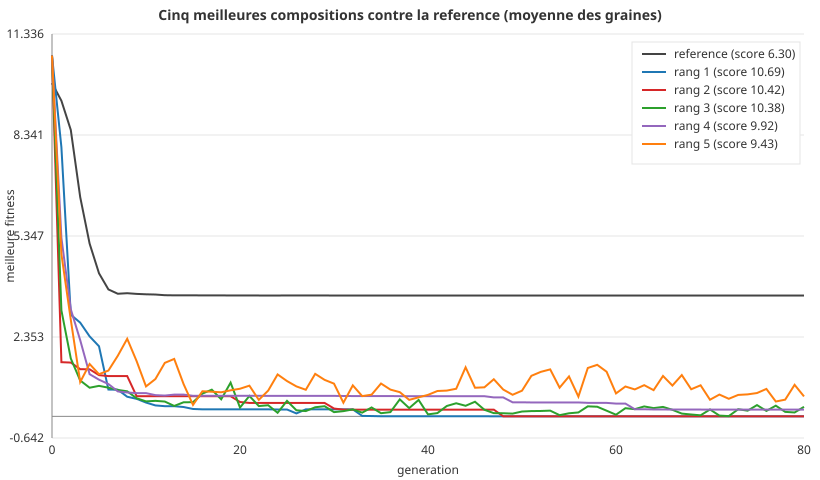

Meilleure fitness moyennee, relevee a quelques generations :


              gen 0     gen 5     gen 10    gen 20    gen 40    gen 80  


  reference   9.879  4.241  3.619  3.584  3.582  3.582


  rang 1      10.694  2.078  0.409  0.208  0.003  0.001


  rang 2      10.694  1.222  0.597  0.425  0.199  0.000


  rang 3      10.694  0.904  0.444  0.260  0.059  0.282


  rang 4      10.694  1.087  0.689  0.609  0.598  0.200


  rang 5      10.694  1.250  0.887  0.819  0.637  0.591


Programme de reference : Seq(Mutate(rate=0.3, scale=0.1), Select(tournament_size=3))


Programme de rang 1    : Repeat(Seq(Select(tournament_size=2), Crossover(rate=0.649), Mutate(rate=0.159, scale=0.324)), n=2)


In [9]:
// Courbe moyenne sur les graines : on lit la FORME de la trajectoire, la dispersion
// entre graines etant gommee. Les statistiques, elles, restent par graine.
double[] MeanHistory(CompositionResult r)
{
    int n = r.Histories[0].Length;
    var mean = new double[n];
    for (int g = 0; g < n; g++) mean[g] = r.Histories.Average(h => h[g]);
    return mean;
}

var xs = Enumerable.Range(0, Gens + 1).Select(g => (double)g).ToArray();
var palette = new[] { "#1f77b4", "#d62728", "#2ca02c", "#9467bd", "#ff7f0e" };

// La reference est evaluee sur 10 graines, les candidates sur 5 : la courbe moyennee
// garde son sens, la comparaison de statistiques, elle, attend la cellule suivante.
var referenceSeries = new SvgSeries(
    $"reference (score {Fmt.Num(canonScore.Score, "0.00")})",
    xs, MeanHistory(canonScore), TraceStyle.Line, "#444444");

var topSeries = new List<SvgSeries> { referenceSeries };
for (int i = 0; i < 5; i++)
{
    var c = ranked[i];
    topSeries.Add(new SvgSeries(
        $"rang {i + 1} (score {Fmt.Num(c.Result.Score, "0.00")})",
        xs, MeanHistory(c.Result), TraceStyle.Line, palette[i]));
}

display(SvgChartHelper.Overlay(
    "Cinq meilleures compositions contre la reference (moyenne des graines)",
    "generation", "meilleure fitness", topSeries, 820, 480));

// Les memes courbes, en chiffres : la figure montre la forme, le tableau la mesure.
int[] marks = { 0, 5, 10, 20, 40, 80 };
Console.WriteLine("Meilleure fitness moyennee, relevee a quelques generations :");
Console.WriteLine("  " + new string(' ', 12) + string.Join("  ", marks.Select(g => $"gen {g,-4}")));
var rows = new (string Name, CompositionResult Result)[]
{
    ("reference", canonScore),
    ("rang 1", ranked[0].Result),
    ("rang 2", ranked[1].Result),
    ("rang 3", ranked[2].Result),
    ("rang 4", ranked[3].Result),
    ("rang 5", ranked[4].Result),
};
foreach (var row in rows)
{
    var mean = MeanHistory(row.Result);
    Console.WriteLine($"  {row.Name,-12}" + string.Join("  ", marks.Select(g => Fmt.Num(mean[g], "0.000"))));
}

Console.WriteLine();
Console.WriteLine("Programme de reference : " + canonProgram.Signature());
Console.WriteLine("Programme de rang 1    : " + ranked[0].Program.Signature());

### Lecture de la figure

Les courbes disent trois choses que le classement ne disait pas.

**Tout le monde part du même point.** À la génération 0, aucune composition n'a encore tourné : la valeur ne dépend que de la population initiale. La référence affiche `9.879` et les candidates `10.694` — l'écart vient uniquement de l'ensemble de graines (dix pour la référence, cinq pour les candidates), pas des programmes. C'est un contrôle utile : si une courbe démarrait ailleurs, c'est que le protocole aurait bougé.

**La référence ne descend pas, elle s'arrête.** `4.241` à la génération 5, `3.619` à la génération 10, puis `3.582` jusqu'au bout. Le plateau est atteint avant la dixième génération et ne se dément plus. Les candidates, elles, **continuent de descendre** : le rang 1 passe de `2.078` (génération 5) à `0.409` (10), `0.208` (20), `0.003` (40), `0.001` (80) — la courbe n'a pas fini de tomber à la fin de la course. Le rang 2 atteint `0.000` : le minimum global est trouvé et conservé.

**Une courbe peut remonter — et ce n'est pas un bug.** Le rang 3 vaut `0.059` à la génération 40 puis `0.282` à la génération 80. La raison est dans la boucle : elle enregistre la meilleure fitness de la population **à chaque génération**, pas le meilleur jamais vu. Comme il n'y a ni élitisme ni réinsertion, rien ne garantit que le meilleur individu d'une génération soit recopié dans la suivante : un tournoi peut l'oublier, et la valeur remonte. C'est exactement le rôle que joue, dans MGS-19, l'opérateur de réinsertion — et son absence ici est délibérée, pour que la trace ne montre que l'effet de la composition.

Conséquence pratique : une composition qui « plonge puis remonte » n'a pas échoué. Elle a remis son meilleur individu en jeu. Si l'on veut mesurer la meilleure solution **jamais atteinte**, il faut cumuler un minimum au fil des générations : c'est l'exercice 2, juste après.

### Exercice 2 : une troisième spécification — la meilleure solution jamais atteinte

Les deux spécifications de la section 4 lisent la courbe telle que la boucle la trace : la meilleure fitness **de la population** à chaque génération. Le rang 3 vient de montrer ce que cette lecture laisse passer — sa courbe remonte, alors que son meilleur individu avait déjà été trouvé.

**Objectif.** Écrire deux fonctions, sans modifier `Evaluate` ni les deux scores existants :

- `CumulativeMin(double[] history)` : la courbe du meilleur jamais atteint, génération après génération ;
- `ScoreBestEver(CompositionResult r)` : un score qui récompense la profondeur du meilleur individu rencontré pendant la course.

Puis classer les trente candidats de la section 5 avec ce score : le podium obtenu se confronte aux trois podiums de la section 7, qui suit.

**Deux objets distincts, qui se ressemblent.** La courbe cumulée qu'affiche la cellule est celle de la courbe **moyenne** de la figure. Le score, lui, cumule **graine par graine** avant de moyenner : minimum et moyenne ne commutent pas, et c'est la seconde écriture qui a un sens pour classer.

**Ce que l'exercice fait manipuler.** Une spécification est une **lecture** d'une trajectoire : changer de lecture, c'est changer ce que « bonne composition » veut dire. `early_dive` pénalise l'instabilité de la seconde moitié ; ce score-là n'a pas à le faire — à vous de voir si c'est une qualité ou un aveuglement, et de le dire.

**Comment vérifier.** La courbe cumulée ne peut jamais remonter : c'est le test de la première fonction. La cellule affiche, pour quelques générations, la courbe du rang 3 et sa version cumulée, puis le podium — avec les stubs, elle n'affiche qu'un message.

In [10]:
// Exercice 2 : une troisieme specification, fondee sur le meilleur jamais atteint.
// Les deux stubs compilent et s'executent tels quels.

// Courbe du meilleur jamais atteint : la valeur a la generation g est le minimum des
// valeurs de history jusqu'a g inclus.
double[] CumulativeMin(double[] history)
{
    // TODO etudiant :
    //   Etape 1 : creer un tableau de la meme longueur que history.
    //   Etape 2 : le parcourir une fois en gardant le minimum rencontre jusqu'ici.
    // Indice : une passe, deux lignes, Math.Min ; ni tri ni LINQ.
    return Array.Empty<double>();
}

// Score moyen sur les graines : profondeur atteinte par le meilleur individu de la course.
double ScoreBestEver(CompositionResult r)
{
    // TODO etudiant :
    //   Etape 1 : appliquer CumulativeMin a chaque histoire de r.Histories.
    //   Etape 2 : mesurer la chute de chaque courbe cumulee (premiere valeur moins derniere).
    //   Etape 3 : en rendre la moyenne sur les graines.
    // Indice : le score doit etre d'autant plus grand que le meilleur jamais atteint est bas.
    return 0.0;
}

var exHistory = MeanHistory(ranked[2].Result);
var exCumul = CumulativeMin(exHistory);
int[] exMarks = { 0, 20, 40, 60, Gens };

Console.WriteLine("Exercice 2 -- la meilleure solution jamais atteinte, rang 3 (moyenne de 5 graines) :");
if (exCumul.Length != exHistory.Length)
{
    Console.WriteLine("  Exercice 2 a completer -- CumulativeMin doit rendre un tableau de la meme longueur que l'histoire recue.");
}
else
{
    var exHead = exMarks.Select(g => $"gen {g}".PadLeft(8));
    var exTraced = exMarks.Select(g => Fmt.Num(exHistory[g], "0.000").PadLeft(8));
    var exBest = exMarks.Select(g => Fmt.Num(exCumul[g], "0.000").PadLeft(8));
    Console.WriteLine("  " + new string(' ', 24) + string.Join("   ", exHead));
    Console.WriteLine("  " + "courbe tracee".PadRight(24) + string.Join("   ", exTraced));
    Console.WriteLine("  " + "meilleur jamais atteint".PadRight(24) + string.Join("   ", exBest));

    var exScored = candidates
        .Select(c => (c.Program, c.Result, BestEver: ScoreBestEver(c.Result)))
        .OrderByDescending(t => t.BestEver)
        .Take(3)
        .ToArray();

    Console.WriteLine();
    if (exScored.All(t => t.BestEver == 0.0))
    {
        Console.WriteLine("  Exercice 2 a completer -- ScoreBestEver rend 0 pour les trente candidats.");
    }
    else
    {
        Console.WriteLine("Podium des 30 candidats, par score du meilleur jamais atteint :");
        foreach (var t in exScored)
            Console.WriteLine($"  score {Fmt.Num(t.BestEver, "0.000"),7}   mediane {Fmt.Num(t.Result.Median, "0.000"),6}   "
                + Truncate(t.Program.Signature(), 70));
    }
}

Exercice 2 -- la meilleure solution jamais atteinte, rang 3 (moyenne de 5 graines) :


  Exercice 2 a completer -- CumulativeMin doit rendre un tableau de la meme longueur que l'histoire recue.


### Comparaison à protocole identique — la main contre la trouvée

Le classement de la section 5 a choisi sur cinq graines. Une composition élue sur un échantillon peut perdre son avance quand l'échantillon s'élargit : les mesures qui font foi sont donc prises **après**, sur vingt graines, et pour tout le monde de la même façon.

Trois compositions passent par ce protocole : la composition « main », écrite à la main après lecture du classement (deux pas de mutation, puis une sélection) ; la composition trouvée au score `early_dive` ; et celle de meilleure médiane à cinq graines. Les trois podiums qui suivent posent ensuite la question que le premier classement laissait ouverte : le critère change-t-il le gagnant ?

Composition ecrite a la main : Seq(Repeat(Mutate(rate=0.3, scale=0.3), n=2), Select(tournament_size=3))


Comparaison a protocole identique (20 graines, 50 individus, 80 generations) :


  approche               mediane  ecart-type    score   fast<5


  main                     0.144       0.332    7.473    0.410


  trouvee (score)          0.001       0.298    8.105    0.510


  trouvee (mediane)        0.000       0.217    7.780    0.600


... (13 outputs left out)

  Podium par mediane finale :


    1. score 10.416, fast<5 0.500, mediane 0.000  Repeat(Repeat(Seq(Select(tournament_size=3), Select(tournament_size...


    2. score 9.921, fast<5 0.383, mediane 0.000  Seq(Switch(early_phase, Parallel(Crossover(rate=0.844), Select(tour...


    3. score 10.690, fast<5 0.367, mediane 0.001  Repeat(Seq(Select(tournament_size=2), Crossover(rate=0.649), Mutate...


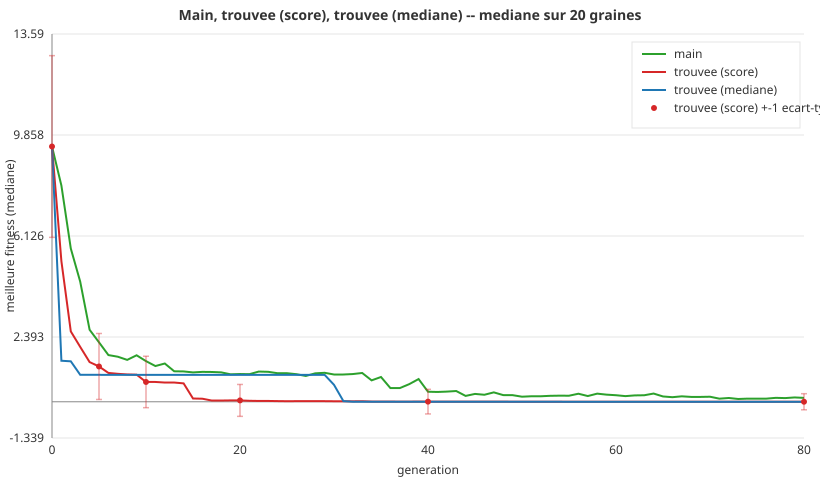

In [11]:
// Comparaison a protocole identique : 20 graines pour tout le monde. Le classement a
// 5 graines a servi a choisir les candidates ; ce sont ces mesures-ci qui font foi.
// "main" est la composition ecrite a la main APRES lecture du classement : deux pas de
// mutation suivis d'une selection, repetes deux fois par generation.
var mainProgram = new Seq(new Repeat(new Mutate(0.3, 0.3), 2), new Select(3));
const int FullSeeds = 20;

var bestProgram = ranked[0].Program;
var bestMedianProgram = candidates.OrderBy(c => c.Result.Median).ThenBy(c => c.Result.Std).First().Program;

var mainResult = Evaluate(mainProgram, nSeeds: FullSeeds, nIndividuals: PopSize, nGenerations: Gens, nDims: Dim);
var bestResult = Evaluate(bestProgram, nSeeds: FullSeeds, nIndividuals: PopSize, nGenerations: Gens, nDims: Dim);
var bestMedianResult = Evaluate(bestMedianProgram, nSeeds: FullSeeds, nIndividuals: PopSize, nGenerations: Gens, nDims: Dim);

Console.WriteLine("Composition ecrite a la main : " + mainProgram.Signature());
Console.WriteLine();
Console.WriteLine($"Comparaison a protocole identique ({FullSeeds} graines, {PopSize} individus, {Gens} generations) :");
Console.WriteLine($"  {"approche",-20}{"mediane",10}{"ecart-type",12}{"score",9}{"fast<5",9}");
foreach (var row in new (string Name, CompositionResult R)[]
{
    ("main", mainResult),
    ("trouvee (score)", bestResult),
    ("trouvee (mediane)", bestMedianResult),
})
{
    Console.WriteLine($"  {row.Name,-20}{Fmt.Num(row.R.Median, "0.000"),10}{Fmt.Num(row.R.Std, "0.000"),12}"
        + $"{Fmt.Num(row.R.Score, "0.000"),9}{Fmt.Num(row.R.FastFirstHit, "0.000"),9}");
}
Console.WriteLine();
Console.WriteLine("Programme trouve (rang 1 au score) :");
Console.WriteLine("  " + bestProgram.Signature());
Console.WriteLine("Programme de meilleure mediane :");
Console.WriteLine("  " + bestMedianProgram.Signature());

// Le critere change-t-il le gagnant ? Les trois classements portent sur les memes
// 30 candidats et les memes 5 graines : seule la cle de tri change.
void ShowPodium(string criterion, IEnumerable<Candidate> ordered)
{
    Console.WriteLine();
    Console.WriteLine($"  Podium par {criterion} :");
    int rank = 0;
    foreach (var c in ordered.Take(3))
    {
        rank++;
        Console.WriteLine($"    {rank}. score {Fmt.Num(c.Result.Score, "0.000")}, "
            + $"fast<5 {Fmt.Num(c.Result.FastFirstHit, "0.000")}, mediane {Fmt.Num(c.Result.Median, "0.000")}  "
            + Truncate(c.Program.Signature(), 70));
    }
}

Console.WriteLine();
Console.WriteLine("Le critere change-t-il le gagnant ? (30 candidats, 5 graines)");
ShowPodium("score early_dive", candidates.OrderByDescending(c => c.Result.Score));
ShowPodium("fast_first_hit", candidates.OrderByDescending(c => c.Result.FastFirstHit));
ShowPodium("mediane finale", candidates.OrderBy(c => c.Result.Median).ThenBy(c => c.Result.Std));

// Courbes medianes (comme le jumeau Python) et dispersion d'une des candidates.
double[] MedianHistory(CompositionResult r)
{
    int n = r.Histories[0].Length;
    var median = new double[n];
    for (int g = 0; g < n; g++) median[g] = Median(r.Histories.Select(h => h[g]).ToArray());
    return median;
}

double[] StdHistory(CompositionResult r)
{
    int n = r.Histories[0].Length;
    var sd = new double[n];
    for (int g = 0; g < n; g++) sd[g] = Std(r.Histories.Select(h => h[g]).ToArray());
    return sd;
}

int[] errorMarks = { 0, 5, 10, 20, 40, 80 };
var errorXs = errorMarks.Select(g => (double)g).ToArray();
var comparisonSeries = new List<SvgSeries>
{
    new SvgSeries("main", xs, MedianHistory(mainResult), TraceStyle.Line, "#2ca02c"),
    new SvgSeries("trouvee (score)", xs, MedianHistory(bestResult), TraceStyle.Line, "#d62728"),
    new SvgSeries("trouvee (mediane)", xs, MedianHistory(bestMedianResult), TraceStyle.Line, "#1f77b4"),
    new SvgSeries("trouvee (score) +-1 ecart-type", errorXs,
        errorMarks.Select(g => MedianHistory(bestResult)[g]).ToArray(), TraceStyle.Markers, "#d62728",
        errorMarks.Select(g => StdHistory(bestResult)[g]).ToArray()),
};

display(SvgChartHelper.Overlay(
    $"Main, trouvee (score), trouvee (mediane) -- mediane sur {FullSeeds} graines",
    "generation", "meilleure fitness (mediane)", comparisonSeries, 820, 480));

### Lecture de la comparaison — ce que la main apporte, et ce que le score cache

**La main rattrape beaucoup, quand elle a lu le classement.** La référence `Seq(Mutate, Select)` plafonnait à une médiane de `3.980`. La composition « main » — deux pas de mutation d'amplitude `0.3`, puis une sélection par tournoi de taille trois — tombe à `0.144` sur vingt graines. Elle n'a été écrite qu'après avoir vu que les gagnants **répétaient** un cycle : c'est la leçon du classement, transférée à la main. Deux choses y ont bougé à la fois par rapport à la référence : la structure (deux pas de mutation au lieu d'un) et le réglage (une amplitude `0.3` au lieu de `0.1`). Le carnet ne les départage pas — il aurait fallu deux compositions pour cela.

**La recherche garde l'avantage, mais de peu.** Les deux compositions trouvées finissent à `0.001` et `0.000` de médiane, contre `0.144` pour la main ; sur le score, `8.105` et `7.780` contre `7.473`. L'avantage est réel et mesuré à protocole identique (vingt graines), pas affirmé. Il est aussi **modeste** : une recherche aléatoire de trente tirages ne bat pas de loin une composition écrite en comprenant ce qu'on fait.

**Le critère change le vainqueur.** C'est le point à retenir. Les trois podiums, calculés sur les mêmes trente candidats et les mêmes cinq graines, ne donnent pas le même premier :

| Classement par | Vainqueur |
|---|---|
| score `early_dive` | `Repeat(Seq(Select, Crossover, Mutate), n=2)` |
| `fast_first_hit` | `Repeat(Repeat(Seq(Select, Select, Mutate), n=3), n=4)` |
| médiane finale | la même que pour `fast_first_hit` |

Le vainqueur au score n'est que **troisième** à la médiane. Autrement dit : « la meilleure composition » n'existe pas sans un critère, et le critère est une décision de l'expérimentateur.

**Le classement à cinq graines surestime son vainqueur.** Le même programme, réévalué sur vingt graines, passe d'un score de `10.690` à `8.105` ; son dauphin passe de `10.416` à `7.780`. Les deux chutent d'environ 2,6 points : les graines 5 à 19 sont simplement plus difficiles que les cinq premières. Un classement obtenu sur un petit nombre de graines lit une différence qui, en partie, n'appartient pas aux programmes.

**Une différence avec le jumeau Python.** Dans le carnet Python, la composition trouvée fait mieux que la main sur la médiane mais moins bien sur le score `early_dive` ; ici, elle fait mieux sur les deux. Ce n'est pas une contradiction : les générateurs aléatoires diffèrent, les trente tirages ne sont pas les mêmes. Le classement d'un tirage dépend du hasard ; le fait que **trois critères donnent trois podiums différents**, lui, se retrouve dans les deux carnets.

### Exercice 3 : une descente gloutonne à la place du tirage

La recherche de la section 5 tire trente programmes **indépendants** et les classe. Rien de ce qu'un tirage apprend ne passe au tirage suivant : c'est un échantillonnage, pas un déplacement. AutoML-Zero procède autrement : il modifie des programmes au hasard et sélectionne périodiquement les meilleurs.

**Objectif.** Écrire deux fonctions, sans toucher aux primitives, aux combinateurs ni à `Evaluate` :

- `MutateProgram(Operator program, Rng rng)` : rendre une variante du programme, un de ses nœuds remplacé par un sous-programme neuf ;
- `GreedySearch(int nIterations, int nMutations, int nSeeds, int seed)` : partir de `canonProgram`, proposer `nMutations` variantes par itération, garder la meilleure **si elle bat le programme courant**, et rendre le programme atteint, son score et le nombre de courses consommées.

**Ce que l'exercice fait manipuler.** La différence entre **échantillonner** un espace et **s'y déplacer**. Une descente gloutonne exploite l'information du voisinage et ne regarde jamais ailleurs : on attend donc d'elle moins de variance et plus de risque d'optimum local. C'est une **hypothèse**, pas un résultat — la cellule mesure le point d'arrivée ; la confronter à des tirages de même budget est le prolongement naturel.

**Comment vérifier.** Le score rendu ne peut pas être inférieur à celui du point de départ. Le budget vaut `nIterations × nMutations × nSeeds` courses : chaque variante évaluée coûte `nSeeds` courses, et l'évaluation du point de départ n'entre pas dans le compte. Ce point de départ est mesuré sur `nSeeds` graines : son score n'est donc pas celui de la section 4, qui portait sur dix graines. La comparaison avec la section 5 n'a de sens qu'à budget égal — la recherche aléatoire y a consommé 150 courses.

**Coût.** Une solution de référence consomme les 60 courses en une seconde et demie environ sur ce poste, contre les 150 courses de la recherche aléatoire. Le protocole n'est pas identique pour autant : les 150 courses de la section 5 évaluent chaque candidat sur cinq graines, celles de l'exercice sur trois.

In [12]:
// Exercice 3 : remplacer la recherche aleatoire par une descente gloutonne dans l'espace
// des programmes. Les deux stubs compilent et s'executent tels quels.

// Rend une variante du programme courant : un de ses noeuds est remplace par un
// sous-programme neuf tire au hasard.
Operator MutateProgram(Operator program, Rng rng)
{
    // TODO etudiant :
    //   Etape 1 : recenser les noeuds remplacables. Les combinateurs exposent leurs enfants
    //             (Children, Child, IfTrue, IfFalse, Left, Right) ; une primitive n'en a pas.
    //   Etape 2 : en choisir un avec rng.NextInt(0, nombre de noeuds).
    //   Etape 3 : reconstruire le programme en remplacant ce seul noeud par un tirage de
    //             GenerateCandidate(rng, 2).
    // Indice : un test de type (program is Seq s) dit de quel combinateur il s'agit ; les
    // parametres numeriques et les predicats se recopient tels quels (N, Predicate).
    return program;
}

// Recherche gloutonne : partir de canonProgram, proposer nMutations variantes par
// iteration, garder la meilleure si elle bat le programme courant.
(Operator Program, double Score, int Budget) GreedySearch(int nIterations = 5, int nMutations = 4,
                                                           int nSeeds = 3, int seed = 42)
{
    // TODO etudiant :
    //   Etape 1 : mesurer le point de depart avec Evaluate(canonProgram, nSeeds: nSeeds).
    //   Etape 2 : a chaque iteration, tirer nMutations variantes avec MutateProgram et les
    //             evaluer de la meme facon.
    //   Etape 3 : garder la meilleure variante si elle bat le programme courant ; compter
    //             nSeeds courses par evaluation de candidat et rendre (programme, score, budget).
    // Indice : le generateur se cree une fois, avec new Rng(seed) ; le point de depart ne
    // compte pas dans le budget.
    return (canonProgram, 0.0, 0);
}

const int ExIterations = 5;
const int ExMutations = 4;
const int ExSeedCount = 3;

var exWatch = System.Diagnostics.Stopwatch.StartNew();
var exStart = Evaluate(canonProgram, nSeeds: ExSeedCount, nIndividuals: PopSize, nGenerations: Gens, nDims: Dim);
var (exProgram, exScore, exBudget) = GreedySearch(ExIterations, ExMutations, ExSeedCount);
exWatch.Stop();

Console.WriteLine("Exercice 3 -- descente gloutonne dans l'espace des programmes :");
Console.WriteLine($"  point de depart : score {Fmt.Num(exStart.Score, "0.000")}   {canonProgram.Signature()}");
Console.WriteLine($"  protocole      : {ExIterations} iterations x {ExMutations} variantes x {ExSeedCount} graines"
    + $" = {ExIterations * ExMutations * ExSeedCount} courses attendues");
Console.WriteLine($"  reference      : la recherche aleatoire de la section 5 a coute {candidates.Length * 5} courses");
if (exBudget == 0)
{
    Console.WriteLine($"  Exercice 3 a completer -- GreedySearch rend le point de depart sans avoir consomme de course"
        + $" ({exWatch.ElapsedMilliseconds} ms).");
}
else
{
    Console.WriteLine($"  point d'arrivee : score {Fmt.Num(exScore, "0.000")}   {Truncate(exProgram.Signature(), 90)}");
    Console.WriteLine($"  budget consomme : {exBudget} courses   duree : {exWatch.ElapsedMilliseconds} ms");
}

Exercice 3 -- descente gloutonne dans l'espace des programmes :


  point de depart : score 8.602   Seq(Mutate(rate=0.3, scale=0.1), Select(tournament_size=3))


  protocole      : 5 iterations x 4 variantes x 3 graines = 60 courses attendues


  reference      : la recherche aleatoire de la section 5 a coute 150 courses


  Exercice 3 a completer -- GreedySearch rend le point de depart sans avoir consomme de course (29 ms).


### Le pont vers le moteur natif — le langage n'est pas une maquette

Tout ce qui précède est un modèle pédagogique : trois primitives, quatre combinateurs, une boucle d'une trentaine de lignes. Il serait légitime de demander si le moteur réel se comporte comme ce modèle.

Il se trouve que les classes existent déjà dans `MetaGeneticSharp`, et que les combinateurs de ce carnet les nomment (`ContainerMetaHeuristic`, `SizeBasedMetaHeuristic`, `SwitchMetaHeuristic` ; `IslandMetaHeuristic` est nommée par le combinateur de l'exercice 1). La cellule suivante fait donc l'inverse du reste du carnet : elle **appelle le moteur natif** sur le même problème, avec la même taille de population et le même nombre de générations.

Deux précautions de lecture :

- le moteur natif exécute un **GA canonique** (`DefaultMetaHeuristic`, sélection élitiste, croisement uniforme, mutation uniforme) : c'est lui qui est comparable à la composition « main », pas aux programmes trouvés ;
- il n'évalue pas la population entière à chaque génération, mais les **enfants** produits : le nombre d'évaluations n'est donc pas identique, et il est **mesuré** plutôt que supposé. C'est ce que compte le décorateur d'évaluation ci-dessous.

La graine du moteur est fixée par `FastRandomRandomization.ResetSeed`, ce qui rend les chiffres reproductibles — condition pour qu'une comparaison entre carnets ait un sens.

In [13]:
// Replique du chromosome double de la serie (MGS-10 a MGS-19) : genes transparents,
// creation et generation d'un gene confiees au RNG du moteur, resemence par graine.
public class DoubleArrayChromosome : ChromosomeBase
{
    private readonly double _min;
    private readonly double _max;

    public DoubleArrayChromosome(double[] values, double min, double max) : base(values.Length)
    {
        _min = min;
        _max = max;
        for (int i = 0; i < values.Length; i++) ReplaceGene(i, new Gene(values[i]));
    }

    public override IChromosome CreateNew()
    {
        var rand = RandomizationProvider.Current;
        var values = new double[Length];
        for (int i = 0; i < Length; i++) values[i] = rand.GetDouble(_min, _max);
        return new DoubleArrayChromosome(values, _min, _max);
    }

    public override Gene GenerateGene(int geneIndex) => new Gene(RandomizationProvider.Current.GetDouble(_min, _max));

    public double[] GetDoubleValues() => GetGenes().Select(g => (double)g.Value).ToArray();
}

// Decorateur d'evaluation : compte les appels reellement faits par le moteur, sans
// changer l'objectif. Le nombre d'evaluations devient une mesure, pas une hypothese.
public sealed class CountingFitness : IFitness
{
    private readonly IFitness _inner;

    public CountingFitness(IFitness inner) { _inner = inner; }

    public int Count { get; private set; }

    public double Evaluate(IChromosome chromosome)
    {
        Count++;
        return _inner.Evaluate(chromosome);
    }
}

public sealed class NativeRun
{
    public double Objective { get; init; }
    public int Evaluations { get; init; }
}

// Une course du moteur natif : GA canonique sur Rastrigin, memes population et
// generations que les compositions. RastriginFitness maximise, donc rend -f.
NativeRun RunNative(int seed)
{
    var counter = new CountingFitness(new RastriginFitness());
    FastRandomRandomization.ResetSeed(seed);
    var adam = new DoubleArrayChromosome(Enumerable.Repeat(0.0, Dim).ToArray(), Lo, Hi);
    var population = new MetaPopulation(PopSize, PopSize, adam);
    var ga = new MetaGeneticAlgorithm(population, counter, new EliteSelection(),
                                      new UniformCrossover(0.5f), new UniformMutation(true),
                                      new DefaultMetaHeuristic());
    ga.Termination = new GenerationNumberTermination(Gens);
    ga.Start();
    double bestFitness = ga.BestChromosome.Fitness ?? double.PositiveInfinity;
    return new NativeRun { Objective = -bestFitness, Evaluations = counter.Count };
}

// Le nombre d'evaluations est releve course par course : le moteur n'evaluate que
// les chromosomes encore sans fitness, donc ce nombre depend des tirages de la graine.
// Un seul total n'aurait pas de sens ; on rend le min, la moyenne et le max.
var nativeWatch = Stopwatch.StartNew();
var nativeFinals = new double[FullSeeds];
var nativeEvaluations = new int[FullSeeds];
for (int s = 0; s < FullSeeds; s++)
{
    var run = RunNative(s);
    nativeFinals[s] = run.Objective;
    nativeEvaluations[s] = run.Evaluations;
}
nativeWatch.Stop();

int loopEvaluationsPerCourse = (Gens + 1) * PopSize;

Console.WriteLine($"Moteur natif MetaGeneticSharp, {FullSeeds} graines :");
Console.WriteLine($"  mediane    = {Fmt.Num(Median(nativeFinals), "0.000")}");
Console.WriteLine($"  ecart-type = {Fmt.Num(Std(nativeFinals), "0.000")}");
Console.WriteLine($"  evaluations par course : min {nativeEvaluations.Min()} / moyenne {Fmt.Num(nativeEvaluations.Average(), "0.0")} / max {nativeEvaluations.Max()}");
Console.WriteLine($"  boucle du carnet       : {loopEvaluationsPerCourse} par course (population entiere a chaque generation)");
Console.WriteLine($"  evaluations au total : {nativeEvaluations.Sum()}");
Console.WriteLine($"  duree totale : {nativeWatch.ElapsedMilliseconds} ms");
Console.WriteLine();
Console.WriteLine("Le meme probleme, vu par les trois executions (mediane sur 20 graines) :");
Console.WriteLine($"  {"execution",-26}{"mediane",10}{"ecart-type",12}");
foreach (var row in new (string Name, double Median, double Std)[]
{
    ("main (composition)", mainResult.Median, mainResult.Std),
    ("trouvee (score)", bestResult.Median, bestResult.Std),
    ("moteur natif", Median(nativeFinals), Std(nativeFinals)),
})
{
    Console.WriteLine($"  {row.Name,-26}{Fmt.Num(row.Median, "0.000"),10}{Fmt.Num(row.Std, "0.000"),12}");
}

Moteur natif MetaGeneticSharp, 20 graines :


  mediane    = 0.153


  ecart-type = 0.242


  evaluations par course : min 2934 / moyenne 3012.7 / max 3084


  boucle du carnet       : 4050 par course (population entiere a chaque generation)


  evaluations au total : 60254


... (2 outputs left out)

  execution                    mediane  ecart-type


  main (composition)             0.144       0.332


  trouvee (score)                0.001       0.298


  moteur natif                   0.153       0.242


### Lecture du pont — le modèle tient, et il ne suffit pas

**Le modèle reproduit le moteur.** La composition « main » obtient une médiane de `0.144`, le moteur natif `0.153`. L'écart (`0.009`) est très inférieur à la dispersion de chacune des deux exécutions (`0.332` et `0.242`) : à cette échelle, les deux ne se distinguent pas. Environ deux cents lignes de modèle retrouvent le comportement du moteur réel — c'est ce qui autorise à raisonner sur le langage plutôt que sur l'implémentation.

**Le moteur natif est même un peu moins cher.** De `2 934` à `3 084` évaluations par course selon la graine, `3 013` en moyenne, contre `4 050` pour la boucle du carnet, à population et générations égales — un quart de moins. La raison est écrite dans le moteur : sa fonction d'évaluation ne calcule la fitness que des chromosomes qui n'en ont pas encore, au lieu de recalculer la population entière à chaque génération. D'où le chiffre qui varie d'une course à l'autre : le nombre d'enfants effectivement neufs n'est pas le même à chaque tirage. La comparaison n'est donc pas faussée en sa faveur — il en fait moins, et arrive au même résultat.

**Et pourtant, la composition trouvée fait plus de cent fois mieux.** `0.001` de médiane, contre `0.144` et `0.153` pour les deux exécutions canoniques. Ce n'est pas le modèle qui gagne, ni le moteur : c'est la **structure** du programme, choisie par la recherche parmi trente tirages. La primitive n'a pas changé, la boucle n'a pas changé, seul l'enchaînement a changé. Le rapport est fragile pour autant : il divise deux médianes dont l'une est arrondie à trois décimales, et il ne dit rien de la queue de distribution.

Trois réserves, qui bornent ce que le pont démontre :

- la comparaison porte sur **une** fonction (Rastrigin 2D) et **une** taille de population ; rien ne dit que le classement se transporte à d'autres paysages ;
- le moteur natif exécute un GA canonique : il n'a pas été construit pour battre une composition, et il ne l'a pas fait ;
- les deux exécutions ne partagent pas leur générateur aléatoire : l'égalité `0.144` / `0.153` est une **concordance de niveau**, pas une identité de trajectoire.

## Conclusion — ce que le carnet démontre, et ce qu'il ne démontre pas

Quatre résultats, tous mesurés par les cellules qui précèdent.

- **Un langage de composition suffit à décrire la boucle.** Le même `Evolve` déroule la référence, les cinq compositions de la figure et les deux programmes de la comparaison, sans une ligne de code propre à l'un d'eux : seule la composition change. C'est ce qui rend une recherche possible — et c'est aussi ce qui la borne, puisque l'espace exploré est celui de ces trois primitives et de ces quatre combinateurs.
- **La main rattrape beaucoup en lisant le classement.** La référence plafonne à une médiane de `3.980` ; la composition « main », écrite après avoir vu que les gagnants répétaient un cycle, tombe à `0.144` sur vingt graines. Deux choses ont bougé ensemble — la structure (deux pas de mutation au lieu d'un) et l'amplitude (`0.3` au lieu de `0.1`) : le carnet ne les départage pas.
- **Le critère décide du vainqueur.** Trois classements des mêmes trente candidats, trois premiers différents ; le vainqueur au score `early_dive` n'est que troisième à la médiane. « La meilleure composition » n'existe pas sans une décision sur ce qu'on mesure.
- **Le modèle reproduit le niveau du moteur, sans en être une copie.** `0.144` contre `0.153` de médiane, un écart très inférieur à la dispersion de chacune des deux exécutions ; et la composition trouvée, elle, descend à `0.001`. Le langage n'explique donc pas la performance : il rend la performance **attribuable à une structure**.

Cinq limites, qui comptent autant que les résultats.

1. **Un seul paysage, un seul protocole.** Rastrigin en deux dimensions, cinquante individus, quatre-vingts générations. Rien ici ne dit ce que ces compositions valent ailleurs.
2. **La recherche est un échantillonnage.** Trente tirages indépendants, classés par un score : aucune information ne passe d'un tirage au suivant. L'exercice 3 en fait une descente gloutonne, et même ainsi le carnet reste loin d'AutoML-Zero, qui modifie des programmes à grande échelle sur des tâches réelles.
3. **Le score est un proxy.** `early_dive` récompense une forme de courbe ; rien ne dit que cette forme soit souhaitable partout. La section 7 le montre : changer de critère change le gagnant.
4. **Le pont compare deux niveaux, pas deux mécanismes.** Le moteur natif exécute un GA canonique (`DefaultMetaHeuristic`) ; le carnet ne construit pas la composition trouvée en classes du moteur. L'égalité de médiane dit que le modèle est fidèle à ce niveau-là, pas que le moteur produirait la même chose avec une autre composition.
5. **Les deux jumeaux ne donnent pas le même vainqueur.** Même plan, mêmes expériences, réalisations aléatoires distinctes : les compositions trouvées diffèrent. Lire l'un comme la réplication de l'autre serait une erreur — c'est leur **désaccord** sur le classement d'un tirage, et leur **accord** sur le fait que le critère décide, qui font la valeur de la paire.

**Coût.** Deux cellules impriment leur durée sur le run committé : la recherche de la section 5 prend `3 943` ms pour 150 courses, et le pont vers le moteur natif `365` ms pour 20 courses. Une course du modèle, isolée, dure `16` ms. Le temps part donc dans l'évaluation, pas dans le langage : composer un programme ne coûte rien, l'évaluer coûte tout. Les exercices s'y ajoutent une fois complétés — la solution de référence de l'exercice 3 consomme soixante courses, une seconde et demie environ.

## Références

- **Fortin, F.-A., De Rainville, F.-M., Gardner, M.-A., Parizeau, M. et Gagné, C.** (2012). *DEAP: Evolutionary Algorithms Made Easy*. Journal of Machine Learning Research 13, 2171-2175. Le texte décrit un cadre où l'algorithme s'écrit en découplant le code de l'évolution du jeu d'opérateurs employé : c'est l'idée que ce carnet reprend, réduite à un mini-langage.
- **Real, E., Liang, C., So, D. R. et Le, Q. V.** (2020). *AutoML-Zero: Evolving Machine Learning Algorithms From Scratch*. Proceedings of the 37th International Conference on Machine Learning, PMLR 119. Le texte représente un algorithme comme un programme composé de fonctions, et cherche dans cet espace en modifiant les programmes au hasard et en sélectionnant périodiquement les meilleurs.
- **Stanley, K. O. et Miikkulainen, R.** (2002). *Evolving Neural Networks through Augmenting Topologies*. Evolutionary Computation 10(2), 99-127. Le texte fait croître la structure d'un réseau par étapes, et attribue son efficacité, entre autres, à la protection des innovations structurelles.
- **Carnets de la série** : MGS-02 (primitives et combinateurs), MGS-04 (modèle insulaire), MGS-11 (synergie d'îles), MGS-19 (réinsertion de Metropolis) — les carnets cités en prérequis ou en renvoi dans ce qui précède.

Ces trois publications sont archivées dans le gisement bibliographique du projet ; le carnet ne leur attribue que ce que leur texte dit.

## À retenir

- **Trois primitives, quatre combinateurs, une boucle.** `Mutate`, `Crossover`, `Select` ; `Seq`, `Repeat`, `Switch`, `ParallelOp` ; `Evolve`. Chaque primitive du langage nomme une classe réelle du moteur, ce qui rend le pont de la section 8 possible.
- **Le canon plafonne vite.** Graine 0 : `12.934` à la génération 0, `0.995` dès la génération 20, jamais mieux ensuite. Sur dix graines : médiane `3.980`, écart-type `2.049`.
- **La lecture du classement paie.** Les deux compositions trouvées finissent à `0.001` et `0.000` de médiane sur vingt graines ; la composition « main », écrite après avoir vu que les gagnants répètent un cycle, à `0.144` — contre `3.980` pour la référence.
- **Le critère choisit le vainqueur.** Trois classements des mêmes candidats, trois premiers ; un podium n'est jamais un résultat absolu.
- **Le pont tient.** Le moteur natif obtient `0.153` de médiane avec de `2 934` à `3 084` évaluations par course (`3 013` en moyenne) ; la boucle du carnet `0.144` pour `4 050` ; la composition trouvée `0.001`. Le modèle est fidèle au niveau du moteur, pas à sa dépense.
- **Ce que rien ici ne prouve.** Qu'un autre paysage classerait ces compositions de la même façon, ni que la descente gloutonne de l'exercice 3 batte le tirage aléatoire à budget égal.

## Vérifiez votre compréhension

1. **Pourquoi `Evolve` lève-t-il une exception quand un programme rend une population d'une autre taille, plutôt que de la tronquer ou de la compléter ?**

   <details><summary>Réponse</summary>

   Parce que la taille de la population est le **budget** du protocole. La boucle réévalue la population entière après chaque étape et compte `pop.Length` évaluations par génération : changer la taille en silence changerait la dépense, donc la comparabilité entre deux compositions. Une exception nomme le programme fautif au lieu de fausser le classement.

   </details>

2. **Le rang 3 remonte entre la génération 40 et la génération 80. A-t-il échoué ? Que mesure une courbe cumulée ?**

   <details><summary>Réponse</summary>

   Non. La boucle n'a ni élitisme ni réinsertion : rien ne recopie le meilleur individu d'une génération dans la suivante, et `history` enregistre le meilleur **de la population** à chaque génération. Une remontée signifie qu'un bon individu a été remis en jeu, pas que le programme a perdu son acquis. La version cumulée (exercice 2) enregistre le meilleur **jamais atteint** — un minimum cumulé, qui ne peut pas remonter.

   </details>

3. **Deux compositions ont la même médiane finale et des scores `early_dive` différents. Laquelle est la meilleure ?**

   <details><summary>Réponse</summary>

   Aucune, tant qu'on n'a pas décidé ce qu'on mesure. Le score `early_dive` récompense une plongée précoce et pénalise l'instabilité de la seconde moitié ; la médiane finale ignore la trajectoire. La section 7 montre les trois podiums : le vainqueur change avec le critère.

   </details>

4. **Que compare exactement le pont de la section 8 ?**

   <details><summary>Réponse</summary>

   Deux niveaux atteints sur le même paysage et le même protocole — cinquante individus, quatre-vingts générations, vingt graines. D'un côté le moteur natif (`DefaultMetaHeuristic`), de l'autre la boucle du carnet avec la composition « main ». Pas deux mécanismes : le moteur n'exécute pas la composition trouvée par la recherche.

   </details>

## Pour aller plus loin

**Carnet suivant.** [MGS-21 — Représentation contre algorithme](MGS-21-Representation-vs-Algorithme.ipynb) : la preuve croisée entre le choix de l'algorithme de recherche et celui de la représentation de l'espace.

**Dans la série.**

- [MGS-04 — Le modèle insulaire](MGS-04-Islands.ipynb) : les sous-populations et les modes de migration du moteur — le modèle que l'exercice 1 fait écrire.
- [MGS-11 — Synergie d'îles](MGS-11-IslandSynergy.ipynb) : ce que des îles hétérogènes apportent quand on exige qu'elles battent leurs constituants.
- [MGS-15 — Analyse de paysage](MGS-15-LandscapeAnalysis.ipynb) : la corrélation fitness-distance, pour prédire la difficulté d'un paysage avant d'y chercher.
- [MGS-19 — Recuit simulé décomposé](MGS-19-MetropolisReinsertion.ipynb) : l'opérateur de réinsertion dont l'absence, ici, laisse les courbes remonter.

**Lectures.** Les trois textes de la section Références — DEAP, AutoML-Zero et NEAT.

**Le moteur.** [MetaGeneticSharp](../MetaGeneticSharp/) — le fork dont les DLL sont chargées par la première cellule ; `ContainerMetaHeuristic`, `SizeBasedMetaHeuristic`, `SwitchMetaHeuristic` et `IslandMetaHeuristic` y sont les combinateurs que ce carnet nomme.